# Proyecto 2 · Potencia AC de la Planta 2 (regresión)

**Objetivo:** construir y evaluar un modelo de regresión que estime la potencia AC de la Planta 2 (`AC_PLANTA_KW`, suma de los 22 inversores) en el siguiente cuarto de hora a partir de las condiciones medidas, y explicar qué variables la determinan.

**Orden del CRISP-DM:** 0 Configuración · 1 Comprensión del negocio · 2 Comprensión de los datos · 3 Preparación de los datos · 4 Modelado · 5 Evaluación · 6 Conclusiones y despliegue · Verificaciones.

# 0. Configuración

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import (r2_score, mean_squared_error, mean_absolute_error,
                             mean_absolute_percentage_error, silhouette_score)
from sklearn.cluster import KMeans

SEMILLA = 42                 # random_state=SEMILLA en todo lo que tenga azar
RUTA = Path("datos")         # aquí van los dos CSV de Kaggle (no se incluyen en el ZIP)

# Estilo de las gráficas
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.figsize": (10, 5), "axes.titlesize": 13,
                     "axes.titleweight": "bold", "axes.labelsize": 11})

print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__,
      "| matplotlib", matplotlib.__version__, "| seaborn", sns.__version__)

numpy 2.4.6 | pandas 3.0.5 | scikit-learn 1.9.1 | matplotlib 3.11.1 | seaborn 0.13.2


# 1. Comprensión del negocio

Una empresa de operación y mantenimiento (O&M) quiere una referencia de cuánta potencia debería entregar la Planta 2 en cada momento según el clima. Sin esa referencia no puede distinguir una caída causada por nubes de una causada por fallas, desconexiones o suciedad.

La generación eléctrica en una planta fotovoltaica se basa en el efecto fotoeléctrico en celdas semiconductoras, donde la potencia eléctrica entregada depende directamente de dos variables físicas principales: la irradiación solar incidente sobre el plano del módulo y la temperatura de la celda o módulo.

* **Dependencia de la irradiación ($G$):** La corriente fotogenerada por un módulo solar es aproximadamente proporcional a la irradiación solar incidente (medida en $\text{kW/m}^2$). En consecuencia, a mayor irradiación sobre el plano del módulo, mayor es la potencia eléctrica producida, manteniendo una relación cuasi lineal en gran parte del rango de operación.
* **Dependencia de la temperatura del módulo ($T_m$):** Aunque la radiación solar calienta los paneles, el aumento de temperatura reduce el voltaje de circuito abierto de las celdas, lo que disminuye la eficiencia de conversión. En módulos de silicio cristalino, la potencia decrece de forma casi lineal con la temperatura por encima de las condiciones estándar de prueba ($25^\circ\text{C}$), con un coeficiente térmico de potencia típico entre $-0{,}3\%/^\circ\text{C}$ y $-0{,}5\%/^\circ\text{C}$. Esto implica que, bajo una misma irradiación, un módulo más caliente va a entregar menos potencia que uno más frío.
* **Desconexiones y fallas de componentes:** Salidas de servicio de inversores, fallas en fusibles, cableado, seguidores o disparos de protecciones hacen que parte de la capacidad instalada deje de aportar potencia aun cuando existe buen recurso solar.
Para evaluar de manera estandarizada el desempeño global de una planta independientemente de su tamaño o ubicación geográfica, se utiliza el ***Performance Ratio* ($PR$)**, definido como la razón entre el rendimiento final del sistema ($Y_f$, energía neta AC producida por unidad de potencia DC nominal instalada) y el rendimiento de referencia ($Y_r$, irradiación total en el plano del módulo dividida por la irradiación de referencia de $1\text{ kW/m}^2$):

$$PR = \frac{Y_f}{Y_r}$$

Al normalizar la producción energética respecto a la irradiación solar disponible, el $PR$ cuantifica el efecto conjunto de todas las pérdidas del sistema (eficiencia del inversor, temperatura, cableado, suciedad, sombreado y fallas o indisponibilidad) y sirve como indicador clave para detectar degradación o anomalías operativas.


**Preguntas analíticas**

1. ¿Los días en que sale el sol más temprano de lo usual, se presentan como datos atípicos válidos?
2. ¿Cuáles son las potencias mínimas que puede registrar un medidor de potencia?
3. ¿Cómo cambia la temperatura del módulo de acuerdo a la irradiancia registrada en el momento?
4. ¿Cuánto mejora el pronóstico frente a la persistencia, cuánto añade el clima a la historia y en qué tipo de día se concentra el error?

# 2. Comprensión de los datos

Se prepara la serie de potencia AC cada 15 minutos. Conservamos las series por inversor para revisar la calidad por equipo y se agrega la potencia para el análisis de la planta. El archivo de sensores aporta la irradiancia, temperatura ambiente y temperatura del módulo al análisis.

## 2.1 Cargar los CSV y convertir las fechas
Los dos datasets usan el mismo formato. `SOURCE_KEY` identifica un inversor en generación y un sensor en meteorología. La unión se hace por **`PLANT_ID` y `DATE_TIME`**, las mediciones meteorológicas son compartidas por los inversores de la planta.

In [4]:
def leer_csv(nombre):
    """Lee un CSV de la carpeta de datos definida en la configuración."""
    return pd.read_csv(nombre)

df2 = leer_csv("Plant_2_Generation_Data.csv")
clima2 = leer_csv("Plant_2_Weather_Sensor_Data.csv")
df_limpio = df2.copy()
sensores = clima2.copy()
for nombre, datos in {"Generación": df_limpio, "Sensores": sensores}.items():
    tipo_original = datos["DATE_TIME"].dtype
    datos["DATE_TIME"] = pd.to_datetime(
        datos["DATE_TIME"], format="%Y-%m-%d %H:%M:%S", errors="coerce")
    datos["PLANT_ID"] = datos["PLANT_ID"].astype(str)
    print(nombre, "|", tipo_original, "→", datos["DATE_TIME"].dtype,
          "| inválidas:", datos["DATE_TIME"].isna().sum(),
          "| rango:", datos["DATE_TIME"].min(), "a", datos["DATE_TIME"].max())
    display(datos.head(3))

Generación | str → datetime64[us] | inválidas: 0 | rango: 2020-05-15 00:00:00 a 2020-06-17 23:45:00


,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD
0,2020-05-15,4136001,4UPUqMRk7TRMgml,0.0,0.0,9425.000000,2.429011e+06
1,2020-05-15,4136001,81aHJ1q11NBPMrL,0.0,0.0,0.000000,1.215279e+09
2,2020-05-15,4136001,9kRcWv60rDACzjR,0.0,0.0,3075.333333,2.247720e+09


Sensores | str → datetime64[us] | inválidas: 0 | rango: 2020-05-15 00:00:00 a 2020-06-17 23:45:00


,DATE_TIME,PLANT_ID,SOURCE_KEY,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15 00:00:00,4136001,iq8k7ZNt4Mwm3w0,27.004764,25.060789,0.0
1,2020-05-15 00:15:00,4136001,iq8k7ZNt4Mwm3w0,26.880811,24.421869,0.0
2,2020-05-15 00:30:00,4136001,iq8k7ZNt4Mwm3w0,26.682055,24.427290,0.0


## 2.2 Ordenar y medir la resolución
Se calcula la diferencia entre mediciones dentro del mismo equipo. Un salto de 30 minutos representa un cuarto de hora ausente. Una diferencia de cero dentro del equipo indica posibles duplicados.

In [5]:
llave_equipo = ["PLANT_ID", "SOURCE_KEY", "DATE_TIME"]
df_limpio = df_limpio.dropna(subset=["DATE_TIME"]).sort_values(llave_equipo)
sensores = sensores.dropna(subset=["DATE_TIME"]).sort_values(llave_equipo)

for nombre, datos in {"Generación": df_limpio, "Sensores": sensores}.items():
    paso = datos.groupby(["PLANT_ID", "SOURCE_KEY"])["DATE_TIME"].diff()
    print(nombre)
    display(paso.dt.total_seconds().div(60).value_counts().sort_index()
            .rename_axis("Intervalo (min)").to_frame("Registros"))

Generación


,Registros
Intervalo (min),
15.0,67556
30.0,106
975.0,10
12630.0,4


Sensores


,Registros
Intervalo (min),
15.0,3253
30.0,5


## 2.3 Duplicados, agregación y unión
La fecha se repite en generación porque los 22 inversores deben reportan al tiempo. Se quitan las copias exactas y se promedian valores de una misma llave en caso de que hayan duplicados exactos de filas. Tomamos la decisión de clasificar un total como completo sólo si todos los equipos se reportan. La unión ya validada evita multiplicar las filas de generación cuando se adjuntan las variables meteorológicas.

In [6]:
y = "AC_POWER"
potencias = ["AC_POWER", "DC_POWER"]
meteorologia = ["IRRADIATION", "AMBIENT_TEMPERATURE", "MODULE_TEMPERATURE"]
llave_fecha = ["PLANT_ID", "DATE_TIME"]
resumen = []

fuentes = {"Generación": (df_limpio, potencias), "Sensores": (sensores, meteorologia)}
limpias_por_llave = {}
for nombre, (datos, columnas) in fuentes.items():
    sin_copias = datos.drop_duplicates()
    copias = len(datos) - len(sin_copias)
    conflictos = sin_copias.duplicated(llave_equipo).sum()
    print(nombre, "| registros:", len(datos), "| fechas repetidas:", datos.duplicated(llave_fecha).sum(),
          "| copias exactas:", copias, "| llaves repetidas tras quitar copias:", conflictos,
          "| equipos:", datos["SOURCE_KEY"].nunique())
    limpias_por_llave[nombre] = sin_copias.groupby(llave_equipo, as_index=False)[columnas].mean()
    resumen.extend([[nombre, "Copias exactas", copias, "Eliminar copias"],
                    [nombre, "Llaves repetidas", conflictos, "Promediar valores de la misma llave"]])

df_limpio = limpias_por_llave["Generación"]
sensores = limpias_por_llave["Sensores"]
assert df_limpio["PLANT_ID"].nunique() == 1
assert df_limpio["PLANT_ID"].iloc[0] == sensores["PLANT_ID"].iloc[0]
meteo_por_fecha = sensores.groupby(llave_fecha, as_index=False)[meteorologia].mean()
numero_equipos = df_limpio["SOURCE_KEY"].nunique()
generacion_por_fecha = df_limpio.groupby(llave_fecha).agg(
    AC_POWER=(y, lambda s: s.sum(min_count=numero_equipos)),
    EQUIPOS_REPORTADOS=("SOURCE_KEY", "nunique")).reset_index()
planta = generacion_por_fecha.merge(meteo_por_fecha, on=llave_fecha, how="outer",
                                    validate="one_to_one", indicator=True)
display(planta["_merge"].value_counts().rename("Instantes"))
display(planta.drop(columns="_merge").head())

Generación | registros: 67698 | fechas repetidas: 64439 | copias exactas: 0 | llaves repetidas tras quitar copias: 0 | equipos: 22
Sensores | registros: 3259 | fechas repetidas: 0 | copias exactas: 0 | llaves repetidas tras quitar copias: 0 | equipos: 1


_merge
both          3259
left_only        0
right_only       0
Name: Instantes, dtype: int64

,PLANT_ID,DATE_TIME,AC_POWER,EQUIPOS_REPORTADOS,IRRADIATION,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE
0,4136001,2020-05-15 00:00:00,0.0,22,0.0,27.004764,25.060789
1,4136001,2020-05-15 00:15:00,0.0,22,0.0,26.880811,24.421869
2,4136001,2020-05-15 00:30:00,0.0,22,0.0,26.682055,24.427290
3,4136001,2020-05-15 00:45:00,0.0,22,0.0,26.500589,24.420678
4,4136001,2020-05-15 01:00:00,0.0,22,0.0,26.596148,25.088210


## 2.4 Completar la rejilla y contar faltantes
Cada cuarto de hora esperado decidimos incluirlo aunque no haya registros. Es decir que se conserva el calendario completo para mantener rezagos correctos. Las barras nos indican lecturas AC ausentes por inversor e instantes de tiempo ausentes por parte del sensor.

Días: 34 | instantes esperados: 3264 | instantes con menos de 22 inversores: 909 | instantes sin inversores: 5


,AC por inversor,Instantes del sensor
DATE_TIME,,
2020-05-15,22,1
2020-05-19,92,1
2020-05-20,602,0
2020-05-21,384,0
2020-05-22,384,0
2020-05-23,384,0
2020-05-24,384,0
2020-05-25,384,0
2020-05-26,384,0


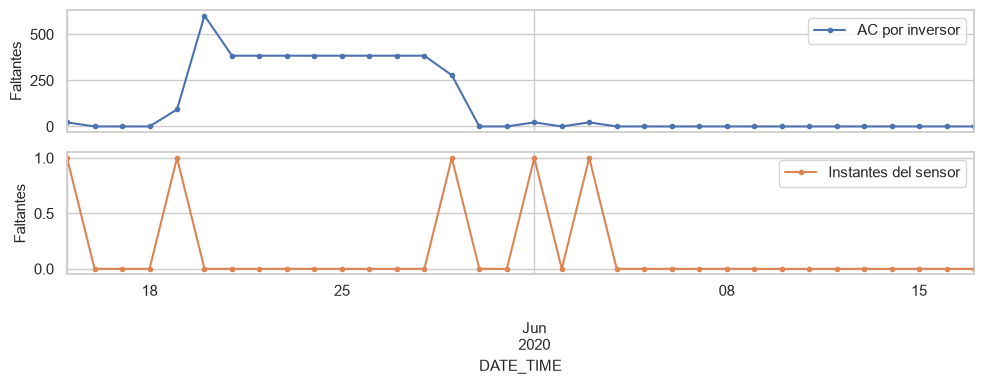

In [7]:
planta = planta.sort_values("DATE_TIME").set_index("DATE_TIME")
completo = pd.date_range(planta.index.min(), planta.index.max(), freq="15min", name="DATE_TIME")
series = {
    col: df_limpio.pivot(index="DATE_TIME", columns="SOURCE_KEY", values=col).reindex(completo)
    for col in potencias
}
clima = planta[meteorologia].reindex(completo)
ac = series[y]
reportaron = ac.notna().sum(axis=1)
faltantes = pd.DataFrame({
    "AC por inversor": ac.isna().sum(axis=1).resample("D").sum(),
    "Instantes del sensor": clima.isna().all(axis=1).resample("D").sum()
})
print("Días:", completo.normalize().nunique(), "| instantes esperados:", len(completo),
      "| instantes con menos de", numero_equipos, "inversores:", reportaron.lt(numero_equipos).sum(),
      "| instantes sin inversores:", reportaron.eq(0).sum())
display(faltantes.loc[faltantes.ne(0).any(axis=1)])
faltantes.plot(subplots=True, marker=".", figsize=(10, 4), ylabel="Faltantes")
plt.tight_layout()
plt.show()
for nombre, cantidad in faltantes.sum().items():
    resumen.append([nombre, "Mediciones ausentes", cantidad, "Conservar la rejilla completa"])

Los picos del gráfico de generación indican días con más huecos entre los inversores. Decidimos conservar estos días para aprovechar los equipos que sí reportaron. A pesar de conservarlos consideramos que para comparar energía diaria se exigen los 96 totales completos, pues sería erroneo comparar valores de diferentes escalas.

## 2.5 Valores imposibles, ceros con sol y señales congeladas
Para los sensores usamos rangos físicos en la escala registrada. En AC y DC revisamos que no sean negativos. Un cero AC con `IRRADIATION > 0.2` queda marcado y lo conservamos, porque un inversor pudo estar detenido aunque hubiera sol. En las señales meteorológicas se buscan cinco o más lecturas idénticas seguidas ya que esto indicaría que el sensor dejó de reportar, además excluimos los ceros nocturnos de irradiancia.

In [8]:
limites = {"IRRADIATION": (0, 1.5), "AMBIENT_TEMPERATURE": (-5, 50),
           "MODULE_TEMPERATURE": (-5, 90)}
display(df_limpio[potencias].describe().round(2))
display(clima.describe().round(3))
for col in potencias:
    fuera = series[col].lt(0)
    series[col] = series[col].mask(fuera)
    resumen.append([col, "Potencia negativa", fuera.sum().sum(), "Convertir a NaN"])

for col, (lo, hi) in limites.items():
    fuera = clima[col].lt(lo) | clima[col].gt(hi)
    clima[col] = clima[col].mask(fuera)
    resumen.append([col, f"Fuera de [{lo}, {hi}]", fuera.sum(), "Convertir a NaN"])
    s = clima[col]
    cambio = s.diff().ne(0)
    largo = s.groupby(cambio.cumsum()).transform("size")
    congelado = s.notna() & largo.ge(5)
    if col == "IRRADIATION":
        congelado &= s.gt(0)
    clima.loc[congelado, col] = np.nan
    resumen.append([col, "Racha idéntica de 5 o más", congelado.sum(), "Convertir a NaN"])

ac = series[y]
cero_con_sol = ac.eq(0).mul(clima["IRRADIATION"].gt(.2), axis=0).astype(bool)
resumen.append([y, "Ceros con irradiancia > 0.2", cero_con_sol.sum().sum(),
                "Marcar y conservar"])
print("Mediciones AC en cero con sol:", cero_con_sol.sum().sum())

# Tabla de rangos físicos
display(pd.DataFrame(limites, index=["Mínimo", "Máximo"]).T)

# ¿Qué inversores tienen ceros con sol?
display(cero_con_sol.sum().sort_values(ascending=False).rename("Ceros con sol"))

# ¿Fallan todos a la vez o de a uno?
simultaneos = cero_con_sol.sum(axis=1)
display(simultaneos[simultaneos > 0].value_counts().sort_index()
        .rename_axis("Inversores en cero").rename("Instantes"))
print("Instantes con sol y los", numero_equipos, "inversores en cero:",
      simultaneos.eq(numero_equipos).sum())

# Decisiones tomadas y registros afectados
display(pd.DataFrame(resumen, columns=["Variable", "Problema", "Registros", "Decisión"]))

,AC_POWER,DC_POWER
count,67698.00,67698.00
mean,241.28,246.70
std,362.11,370.57
min,0.00,0.00
25%,0.00,0.00
50%,0.00,0.00
75%,438.22,446.59
max,1385.42,1420.93


,IRRADIATION,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE
count,3259.000,3259.000,3259.000
mean,0.233,28.069,32.772
std,0.313,4.062,11.344
min,0.000,20.942,20.265
25%,0.000,24.602,23.717
50%,0.019,26.981,27.535
75%,0.439,31.057,40.481
max,1.099,39.182,66.636


Mediciones AC en cero con sol: 3758


,Mínimo,Máximo
IRRADIATION,0.0,1.5
AMBIENT_TEMPERATURE,-5.0,50.0
MODULE_TEMPERATURE,-5.0,90.0


SOURCE_KEY
LYwnQax7tkwH5Cb    318
Et9kgGMDl729KT4    305
Quc1TzYxW2pYoWX    279
rrq4fwE8jgrTyWY    267
81aHJ1q11NBPMrL    244
q49J1IKaHRwDQnt    239
9kRcWv60rDACzjR    207
xoJJ8DcxJEcupym    204
WcxssY2VbP4hApt    202
LlT2YUhhzqhg5Sw    199
oZZkBaNadn6DNKz    179
PeE6FRyGXUgsRhN    179
V94E5Ben1TlhnDV    170
vOuJvMaM2sgwLmb    166
oZ35aAeoifZaQzV    134
4UPUqMRk7TRMgml    125
Qf4GUc1pJu5T6c6    123
Mx2yZCDsyf6DPfv    107
NgDl19wMapZy17u     35
mqwcsP2rE7J0TFp     30
IQ2d7wF4YD8zU1Q     23
xMbIugepa2P7lBB     23
Name: Ceros con sol, dtype: int64

Inversores en cero
1      71
2      29
3      28
4      45
5      49
6      62
7      71
8     102
9      88
10     43
15      1
22      9
Name: Instantes, dtype: int64

Instantes con sol y los 22 inversores en cero: 9


,Variable,Problema,Registros,Decisión
0,Generación,Copias exactas,0,Eliminar copias
1,Generación,Llaves repetidas,0,Promediar valores de la misma llave
2,Sensores,Copias exactas,0,Eliminar copias
3,Sensores,Llaves repetidas,0,Promediar valores de la misma llave
4,AC por inversor,Mediciones ausentes,4110,Conservar la rejilla completa
5,Instantes del sensor,Mediciones ausentes,5,Conservar la rejilla completa
6,AC_POWER,Potencia negativa,0,Convertir a NaN
7,DC_POWER,Potencia negativa,0,Convertir a NaN
8,IRRADIATION,"Fuera de [0, 1.5]",0,Convertir a NaN
9,IRRADIATION,Racha idéntica de 5 o más,0,Convertir a NaN


In [9]:
# Solo instantes con sol: los ceros nocturnos son estructurales y deformarían cuartiles, media y desviación
con_sol = clima["IRRADIATION"].gt(.2)
datos = clima.assign(AC_PLANTA_KW=series[y].sum(axis=1, min_count=numero_equipos))[con_sol]

q1, q3 = datos.quantile(.25), datos.quantile(.75)
iqr = q3 - q1
inf, sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
atipico_iqr = datos.lt(inf) | datos.gt(sup)
atipico_z = ((datos - datos.mean()) / datos.std()).abs().gt(3)

display(pd.DataFrame({"Límite inf. IQR": inf, "Límite sup. IQR": sup,
                      "Atípicos IQR": atipico_iqr.sum(), "Atípicos |z| > 3": atipico_z.sum()}).round(3))
display(datos[atipico_iqr.any(axis=1) | atipico_z.any(axis=1)])  # para revisarlos caso por caso

for col in datos:
    resumen.append([col, "Atípicos IQR (con sol)", atipico_iqr[col].sum(), "Marcar y revisar"])
    resumen.append([col, "Atípicos |z| > 3 (con sol)", atipico_z[col].sum(), "Marcar y revisar"])

,Límite inf. IQR,Límite sup. IQR,Atípicos IQR,Atípicos |z| > 3
IRRADIATION,-0.238,1.420,0,0
AMBIENT_TEMPERATURE,20.580,41.966,0,0
MODULE_TEMPERATURE,16.592,73.508,0,0
AC_PLANTA_KW,1800.013,23807.304,18,12


,IRRADIATION,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,AC_PLANTA_KW
DATE_TIME,,,,
2020-05-31 12:45:00,0.860170,34.748582,54.456130,24233.941429
2020-05-31 13:15:00,0.960394,35.987415,64.142721,25409.596667
2020-05-31 13:45:00,0.899076,36.074381,62.141483,24214.880476
2020-05-31 14:00:00,0.918781,36.761355,62.751713,24595.294286
2020-06-01 10:15:00,0.918448,29.822623,50.489643,24514.154286
2020-06-01 12:30:00,0.917015,32.713622,49.316922,25979.760476
2020-06-02 12:30:00,1.083227,31.939592,62.564306,0.000000
2020-06-02 16:15:00,0.378067,31.645158,42.855667,0.000000
2020-06-02 16:30:00,0.417623,32.095935,42.765473,0.000000


In [10]:
# Detalle: una fila por cada (instante, inversor) en cero con sol
ceros_con_sol = cero_con_sol.stack().loc[lambda s: s].index.to_frame(index=False)
ceros_con_sol.to_csv("ceros_con_sol.csv", index=False)

# Resumen por instante, unido a la tabla de la planta
planta = planta.join(cero_con_sol.sum(axis=1).rename("INVERSORES_CERO_SOL"))

assert len(ceros_con_sol) == cero_con_sol.sum().sum()
display(ceros_con_sol.groupby("SOURCE_KEY").size().sort_values(ascending=False).rename("Instantes en cero con sol"))

SOURCE_KEY
LYwnQax7tkwH5Cb    318
Et9kgGMDl729KT4    305
Quc1TzYxW2pYoWX    279
rrq4fwE8jgrTyWY    267
81aHJ1q11NBPMrL    244
q49J1IKaHRwDQnt    239
9kRcWv60rDACzjR    207
xoJJ8DcxJEcupym    204
WcxssY2VbP4hApt    202
LlT2YUhhzqhg5Sw    199
oZZkBaNadn6DNKz    179
PeE6FRyGXUgsRhN    179
V94E5Ben1TlhnDV    170
vOuJvMaM2sgwLmb    166
oZ35aAeoifZaQzV    134
4UPUqMRk7TRMgml    125
Qf4GUc1pJu5T6c6    123
Mx2yZCDsyf6DPfv    107
NgDl19wMapZy17u     35
mqwcsP2rE7J0TFp     30
IQ2d7wF4YD8zU1Q     23
xMbIugepa2P7lBB     23
Name: Instantes en cero con sol, dtype: int64

# 3. Preparación de los datos

## 3.1 Atípicos por hora y revisión física
Se comparan el IQR global (`k = 1.5`) y el IQR por hora (`k = 3`). Para AC y DC se dejan en la tabla la irradiancia, la potencia complementaria y el cociente potencia/irradiancia con sol. Para el sensor, se registra la diferencia entre temperatura del módulo y ambiente.

In [11]:
def limites_iqr(s, k=1.5):
    q1, q3 = s.quantile(.25), s.quantile(.75)
    return q1 - k * (q3 - q1), q3 + k * (q3 - q1)

def atipico_por_hora(s, k=3):
    q1 = s.groupby(s.index.hour).transform(lambda valores: valores.quantile(.25))
    q3 = s.groupby(s.index.hour).transform(lambda valores: valores.quantile(.75))
    iqr = q3 - q1
    return s.lt(q1 - k * iqr) | s.gt(q3 + k * iqr)

hallazgos = []
for variable, matriz in {**series, **{col: clima[[col]].rename(columns={col: "Sensor"}) 
                                      for col in meteorologia}}.items():
    globales = por_hora = 0
    for equipo, s in matriz.items():
        marca = atipico_por_hora(s)
        por_hora += marca.sum()
        fechas = s.index[marca]
        tabla = pd.DataFrame({"equipo": equipo, "variable": variable, "valor": s.loc[fechas],
                              "irradiancia": clima.loc[fechas, "IRRADIATION"],
                              "módulo menos ambiente": (clima["MODULE_TEMPERATURE"] -
                                                        clima["AMBIENT_TEMPERATURE"]).loc[fechas],
                              "decisión": "Conservar; confirmar con contexto físico"})
        if variable in potencias:
            otra = "DC_POWER" if variable == y else y
            tabla["potencia complementaria"] = series[otra].loc[fechas, equipo]
            tabla["potencia / irradiancia"] = tabla["valor"].div(
                tabla["irradiancia"].where(tabla["irradiancia"].gt(.2)))
        hallazgos.append(tabla)
    print(variable, "| por hora:", por_hora)
    resumen.append([variable, "Atípicos por hora", por_hora, "Marcar y conservar"])
atipicos = pd.concat(hallazgos).sort_index()
display(atipicos.head(8).round(3))

display(atipicos.index.hour.value_counts().sort_index())

display(atipicos.groupby(["variable", "equipo"]).size().unstack(0).fillna(0).astype(int))

AC_POWER | por hora: 17
DC_POWER | por hora: 17
IRRADIATION | por hora: 89
AMBIENT_TEMPERATURE | por hora: 2
MODULE_TEMPERATURE | por hora: 0


,equipo,variable,valor,irradiancia,módulo menos ambiente,decisión,potencia complementaria,potencia / irradiancia
DATE_TIME,,,,,,,,
2020-05-15 05:45:00,Sensor,IRRADIATION,0.003,0.003,-0.955,Conservar; confirmar con contexto físico,NaN,NaN
2020-05-15 20:45:00,Sensor,IRRADIATION,0.000,0.000,-1.677,Conservar; confirmar con contexto físico,NaN,NaN
2020-05-16 05:45:00,Sensor,IRRADIATION,0.001,0.001,-2.235,Conservar; confirmar con contexto físico,NaN,NaN
2020-05-16 19:00:00,Sensor,IRRADIATION,0.001,0.001,-2.505,Conservar; confirmar con contexto físico,NaN,NaN
2020-05-16 19:15:00,Sensor,IRRADIATION,0.000,0.000,-0.846,Conservar; confirmar con contexto físico,NaN,NaN
2020-05-17 04:15:00,Sensor,IRRADIATION,0.000,0.000,-1.516,Conservar; confirmar con contexto físico,NaN,NaN
2020-05-17 22:15:00,Sensor,IRRADIATION,0.002,0.002,-1.878,Conservar; confirmar con contexto físico,NaN,NaN
2020-05-17 22:30:00,Sensor,IRRADIATION,0.002,0.002,-1.645,Conservar; confirmar con contexto físico,NaN,NaN


DATE_TIME
0      4
1      1
2      1
3      9
4      5
5     59
12     2
19    17
20    12
21     6
22     6
23     3
Name: count, dtype: int64

variable,AC_POWER,AMBIENT_TEMPERATURE,DC_POWER,IRRADIATION
equipo,,,,
4UPUqMRk7TRMgml,2,0,2,0
81aHJ1q11NBPMrL,2,0,2,0
9kRcWv60rDACzjR,1,0,1,0
Et9kgGMDl729KT4,1,0,1,0
IQ2d7wF4YD8zU1Q,1,0,1,0
LYwnQax7tkwH5Cb,1,0,1,0
Mx2yZCDsyf6DPfv,1,0,1,0
Quc1TzYxW2pYoWX,1,0,1,0
Sensor,0,2,0,89


In [12]:
pot = atipicos[atipicos["variable"] == "AC_POWER"]
display(pot.index.value_counts().rename("Inversores marcados"))
display(pot[["equipo", "valor", "irradiancia", "potencia / irradiancia"]].round(3))

DATE_TIME
2020-06-02 05:45:00    10
2020-05-22 05:45:00     7
Name: Inversores marcados, dtype: int64

,equipo,valor,irradiancia,potencia / irradiancia
DATE_TIME,,,,
2020-05-22 05:45:00,4UPUqMRk7TRMgml,0.527,0.002,NaN
2020-05-22 05:45:00,oZ35aAeoifZaQzV,0.473,0.002,NaN
2020-05-22 05:45:00,vOuJvMaM2sgwLmb,0.540,0.002,NaN
2020-05-22 05:45:00,Mx2yZCDsyf6DPfv,0.587,0.002,NaN
2020-05-22 05:45:00,Quc1TzYxW2pYoWX,0.387,0.002,NaN
2020-05-22 05:45:00,9kRcWv60rDACzjR,0.500,0.002,NaN
2020-05-22 05:45:00,81aHJ1q11NBPMrL,0.520,0.002,NaN
2020-06-02 05:45:00,4UPUqMRk7TRMgml,0.527,0.002,NaN
2020-06-02 05:45:00,xMbIugepa2P7lBB,0.520,0.002,NaN


## 3.2 Rellenar faltantes
Decidimos interpolar en el tiempo huecos interiores de hasta cuatro registros (es decir, una hora). Esa serie sirve para la exploración ya que la interpolación consulta el dato posterior. Para potencia AC comparamos también **cero** y **semana anterior**. La segunda opción que evaluamos copia el valor de ese inversor 672 intervalos antes (una semana) y conserva el hueco cuando falta el dato donante.

In [13]:
def rellenar_huecos_cortos(s, max_pasos=4):
    falta = s.isna()
    tramo = (falta != falta.shift()).cumsum()
    largo = falta.groupby(tramo).transform("sum")
    corto = falta & (largo <= max_pasos)
    return s.where(~corto, s.interpolate(method="time", limit_area="inside"))

ac = series[y]
dc = series["DC_POWER"]
ac_limpia = ac.apply(rellenar_huecos_cortos)
dc_limpia = dc.apply(rellenar_huecos_cortos)
clima_limpio = clima.apply(rellenar_huecos_cortos)
opciones = {"Cero": ac.fillna(0), "Semana anterior": ac.fillna(ac.shift(7 * 96))}
rellenos = []
for metodo, matriz in {**opciones, "Interpolación ≤ 1 h": ac_limpia}.items():
    imputado = ac.isna() & matriz.notna()
    nuevos = imputado.sum().sum()
    pendientes = matriz.isna().sum().sum()
    rellenos.append([metodo, nuevos, pendientes])
    resumen.append([y, "Imputadas con " + metodo, nuevos, f"Quedan {pendientes} huecos"])
display(pd.DataFrame(rellenos, columns=["Método AC", "Rellenadas", "Sin rellenar"]))
display(pd.DataFrame({"Rellenadas": (clima.isna() & clima_limpio.notna()).sum(),
                      "Sin rellenar": clima_limpio.isna().sum()}))
resumen.append(["DC_POWER", "Imputadas con interpolación ≤ 1 h",
                (dc.isna() & dc_limpia.notna()).sum().sum(),
                f"Quedan {dc_limpia.isna().sum().sum()} huecos"])
for col in meteorologia:
    resumen.append([col, "Imputadas con interpolación ≤ 1 h",
                    (clima[col].isna() & clima_limpio[col].notna()).sum(),
                    f"Quedan {clima_limpio[col].isna().sum()} huecos"])

,Método AC,Rellenadas,Sin rellenar
0,Cero,4110,0
1,Semana anterior,2062,2048
2,Interpolación ≤ 1 h,106,4004


,Rellenadas,Sin rellenar
IRRADIATION,5,0
AMBIENT_TEMPERATURE,5,0
MODULE_TEMPERATURE,5,0


#### Comparación Cero frente a semana anterior
Ocultamos los bloques observados completos de **14:00 a 17:00** (12 mediciones) en los últimos cinco días para realizar una comparación de ambos métodos. El error absoluto medio (MAE) usa los mismos puntos para ambos métodos. Esta prueba mide qué tan bien se reconstruye esa franja.

In [14]:
def comparar(horas):
    """Oculta bloques completos de 14:00 a 14:00+horas en los últimos 5 días y mide el MAE de cada método."""
    pasos = 4 * horas
    corte = completo.max().normalize() - pd.Timedelta(days=4)
    franja = (ac.index >= corte) & (ac.index.hour >= 14) & (ac.index.hour < 14 + horas)
    ventanas = ac.loc[franja]
    bloques = ventanas.notna().groupby(ventanas.index.normalize()).transform("sum").eq(pasos)
    oculto = ac.copy()
    oculto.loc[franja] = ventanas.mask(bloques)
    real = ac.where(ac.notna() & oculto.isna())
    assert real.notna().sum().sum() > 0, f"No hubo bloques completos de {horas} h para ocultar"
    metodos = {"Cero": oculto.fillna(0),
               "Semana anterior": oculto.fillna(oculto.shift(7 * 96)),
               "Interpolación ≤ 1 h": oculto.apply(rellenar_huecos_cortos)}
    comunes = real.notna() & metodos["Semana anterior"].notna()  # puntos donde existe el dato de hace una semana
    filas = []
    for metodo, calculado in metodos.items():
        estimadas = real.notna() & calculado.notna()
        usados = comunes & estimadas
        mae = (real - calculado).abs().where(usados).stack().mean()
        filas.append([f"{horas} h", metodo, real.notna().sum().sum(),
                      estimadas.sum().sum(), usados.sum().sum(), mae])
    return filas

comparacion = pd.DataFrame(comparar(1) + comparar(3),
                           columns=["Hueco", "Método", "Ocultadas", "Estimadas", "Comparadas", "MAE (kW)"])
display(comparacion.round(2))

,Hueco,Método,Ocultadas,Estimadas,Comparadas,MAE (kW)
0,1 h,Cero,440,440,440,498.16
1,1 h,Semana anterior,440,440,440,461.15
2,1 h,Interpolación ≤ 1 h,440,440,440,228.51
3,3 h,Cero,1320,1320,1320,455.58
4,3 h,Semana anterior,1320,1320,1320,289.52
5,3 h,Interpolación ≤ 1 h,1320,0,0,NaN


Tomamos la decisión apicar como método para rellenar la interpolación para huecos de 1 hora o menos ya que según la prueba esta presenta el menor MAE. Sin embargo, para huecos largos la interpolación falla. Si bien Semana anterior es bueno para huecos de 3 horas, esta se equivoca casi 2/3 del valor real, además se suma que el clima de hace una semana no tiene nada que ver con el de hoy, lo que lleva a grandes errores. Esto nos lleva a la desición de que los huecos grandes no se deben rellenar y deben ser excluidos.

## 3.3 Resumen de la limpieza y dataset limpio
El CSV de salida contiene una fila por inversor y cuarto de hora. Incluye AC y DC originales, AC y DC con interpolación de huecos cortos, los rellenos AC alternativos y las tres variables del sensor. Además conservamos las marcas de faltantes para distinguir las mediciones de los valores estimados.

In [15]:
display(pd.DataFrame(resumen, columns=["Variable o fuente", "Hallazgo", "Cantidad", "Decisión"]))

salida = pd.concat({
    "AC_OBSERVADA": ac.stack(),
    "DC_OBSERVADA": dc.stack(),
    "AC_INTERPOLADA_CORTOS": ac_limpia.stack(),
    "DC_INTERPOLADA_CORTOS": dc_limpia.stack(),
    "AC_RELLENO_CERO": opciones["Cero"].stack(),
    "AC_RELLENO_SEMANAL": opciones["Semana anterior"].stack(),
    "AC_CERO_CON_SOL": cero_con_sol.stack()
}, axis=1).reset_index()
salida["AC_FALTANTE_ORIGINAL"] = salida["AC_OBSERVADA"].isna()
salida["PLANT_ID"] = df_limpio["PLANT_ID"].iloc[0]
clima_salida = clima_limpio.assign(SENSOR_IMPUTADO=(clima.isna() & clima_limpio.notna()).any(axis=1))
salida = salida.merge(clima_salida.reset_index().assign(PLANT_ID=salida["PLANT_ID"].iloc[0]),
                      on=llave_fecha, how="left", validate="many_to_one")
salida = salida.sort_values(["DATE_TIME", "SOURCE_KEY"])
salida.to_csv("Planta_2_Semana_2_Datos_Limpios.csv", index=False)
print("Planta_2_Semana_2_Datos_Limpios.csv | filas:", len(salida))

,Variable o fuente,Hallazgo,Cantidad,Decisión
0,Generación,Copias exactas,0,Eliminar copias
1,Generación,Llaves repetidas,0,Promediar valores de la misma llave
2,Sensores,Copias exactas,0,Eliminar copias
3,Sensores,Llaves repetidas,0,Promediar valores de la misma llave
4,AC por inversor,Mediciones ausentes,4110,Conservar la rejilla completa
5,Instantes del sensor,Mediciones ausentes,5,Conservar la rejilla completa
6,AC_POWER,Potencia negativa,0,Convertir a NaN
7,DC_POWER,Potencia negativa,0,Convertir a NaN
8,IRRADIATION,"Fuera de [0, 1.5]",0,Convertir a NaN
9,IRRADIATION,Racha idéntica de 5 o más,0,Convertir a NaN


Planta_2_Semana_2_Datos_Limpios.csv | filas: 71808


## 3.4 Exploración de la serie preparada

La exploración se hace después del relleno porque el perfil diario y la energía usan la serie con huecos cortos interpolados. Las correlaciones y los rezagos (secciones 3.4 y 3.5) usan las observaciones originales y justifican qué predictores entran en la tabla de modelado (3.7).

### Perfil diario, mapa, energía y componentes
Usamos el total de planta después de interpolar huecos cortos por inversor según lo decidido. Los días con huecos pendientes quedan fuera de la comparación de energía. La integral diaria multiplica la potencia por 0,25 h y se expresa en kWh.

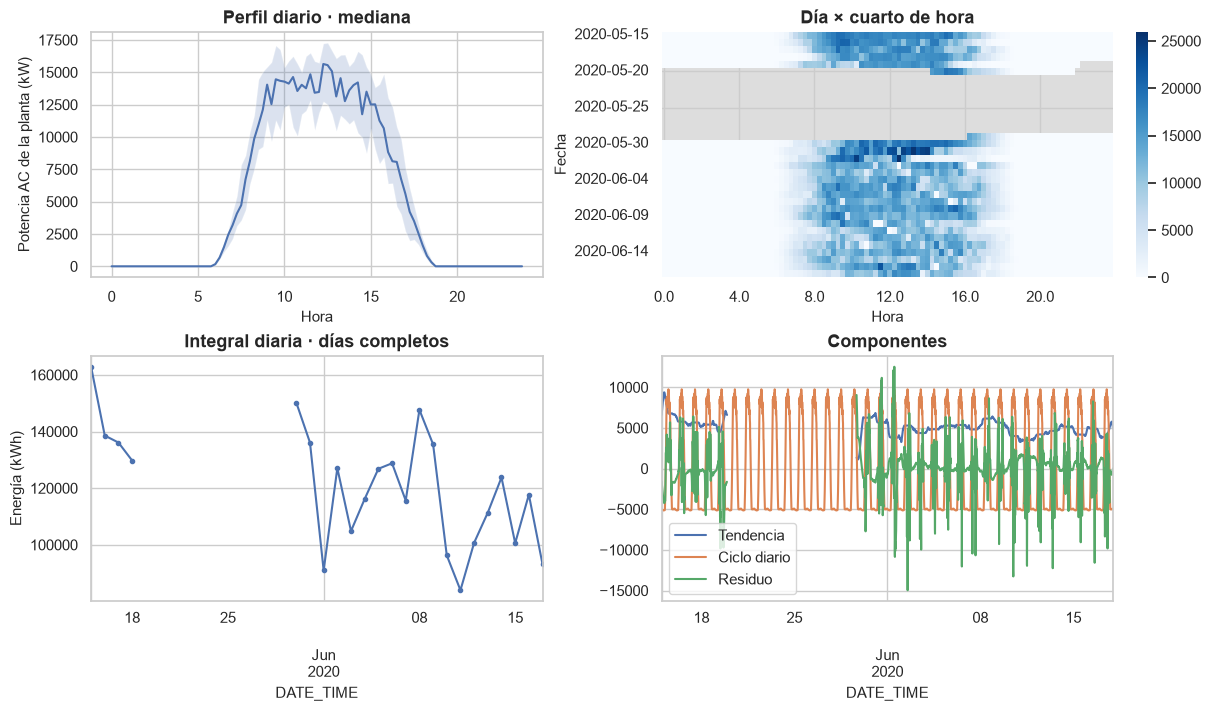

Pico mediano a las 12:15 | días completos: 23 | días incompletos: 11


,AC promedio diario
DATE_TIME,
2020-05-15,6785.8
2020-05-16,5773.5
2020-05-17,5670.8


,Desviación estándar
Serie,6412.0
Tendencia,1003.7
Ciclo diario,5846.5
Residuo,2597.5


Días atípicos por bajo rendimiento frente al sol (IQR):


,Integral AC,Irradiancia media,AC / irradiancia,Ceros con sol (inversor·instante)
DATE_TIME,,,,


In [16]:
df = clima_limpio.assign(AC_POWER=ac_limpia.sum(axis=1, min_count=numero_equipos))
hora_dia = df.index.hour + df.index.minute / 60
perfil = df.groupby(hora_dia)[y].quantile([.25, .5, .75]).unstack()
tabla = df.pivot_table(index=df.index.date, columns=hora_dia, values=y, dropna=False)
diario = df[y].resample("D").mean()
energia = df[y].resample("D").sum(min_count=96) * .25
tendencia = df[y].rolling(96, center=True, min_periods=48).mean()
sin_tendencia = df[y] - tendencia
ciclo = sin_tendencia.groupby(hora_dia).transform("mean")
residuo = df[y] - tendencia - ciclo
partes = pd.DataFrame({"Serie": df[y], "Tendencia": tendencia,
                        "Ciclo diario": ciclo, "Residuo": residuo})

fig, ejes = plt.subplots(2, 2, figsize=(12, 7), layout="constrained")
perfil[.5].plot(ax=ejes[0,0], title="Perfil diario · mediana", xlabel="Hora", ylabel="Potencia AC de la planta (kW)")
ejes[0,0].fill_between(perfil.index, perfil[.25], perfil[.75], alpha=.2)
ejes[0,1].set_facecolor("#ddd")
sns.heatmap(tabla, cmap="Blues", ax=ejes[0,1], xticklabels=16, yticklabels=5)
ejes[0,1].set(title="Día × cuarto de hora", xlabel="Hora", ylabel="Fecha")
energia.plot(ax=ejes[1,0], marker=".", title="Integral diaria · días completos", ylabel="Energía (kWh)")
partes[["Tendencia", "Ciclo diario", "Residuo"]].plot(ax=ejes[1,1], title="Componentes")
plt.show()
pico = int(perfil[.5].idxmax() * 60)
print(f"Pico mediano a las {pico // 60:02d}:{pico % 60:02d} | "
      f"días completos: {energia.notna().sum()} | días incompletos: {energia.isna().sum()}")
display(diario.head(3).to_frame("AC promedio diario").round(1))
display(partes.std().to_frame("Desviación estándar").round(1))
revision_diaria = pd.DataFrame({"Integral AC": energia,
                                 "Irradiancia media": clima_limpio["IRRADIATION"].resample("D").mean()})

revision_diaria["AC / irradiancia"] = revision_diaria["Integral AC"] / revision_diaria["Irradiancia media"]
revision_diaria["Ceros con sol (inversor·instante)"] = cero_con_sol.sum(axis=1).resample("D").sum()

r = revision_diaria["AC / irradiancia"]
q1, q3 = r.quantile([.25, .75])
print("Días atípicos por bajo rendimiento frente al sol (IQR):")
display(revision_diaria[r.lt(q1 - 1.5 * (q3 - q1)) | r.gt(q3 + 1.5 * (q3 - q1))].round(3))

El perfil muestra la curva solar típica y sus cuartiles. Las zonas grises del mapa indican falta de cobertura. Los datos de irradiancia aportan contexto para revisar los días de menor generación. La desviación estándar permite comparar la magnitud del ciclo diario con la tendencia y el residuo.

## 3.5 Correlaciones y dispersiones en horas de sol
Se usan las observaciones originales para correlacionar la potencia total de la planta con las mediciones de su sensor. Se filtran horas con irradiancia superior a 0.05, el mismo umbral que define las horas de sol en el modelo. La temperatura del módulo suele variar junto con la irradiancia. Las asociaciones se leen teniendo en cuenta que las variables meteorológicas también están relacionadas entre sí.

`DC_POWER` aparece solo como verificación (AC ≈ 98 % de DC, sin error de escala): se mide en el mismo instante que el objetivo, así que **no es predictor** (sería fuga).

,AC_POWER,IRRADIATION,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,DC_POWER
AC_POWER,1.000,0.809,0.489,0.726,1.000
IRRADIATION,0.809,1.000,0.498,0.897,0.811
AMBIENT_TEMPERATURE,0.489,0.498,1.000,0.783,0.489
MODULE_TEMPERATURE,0.726,0.897,0.783,1.000,0.727
DC_POWER,1.000,0.811,0.489,0.727,1.000


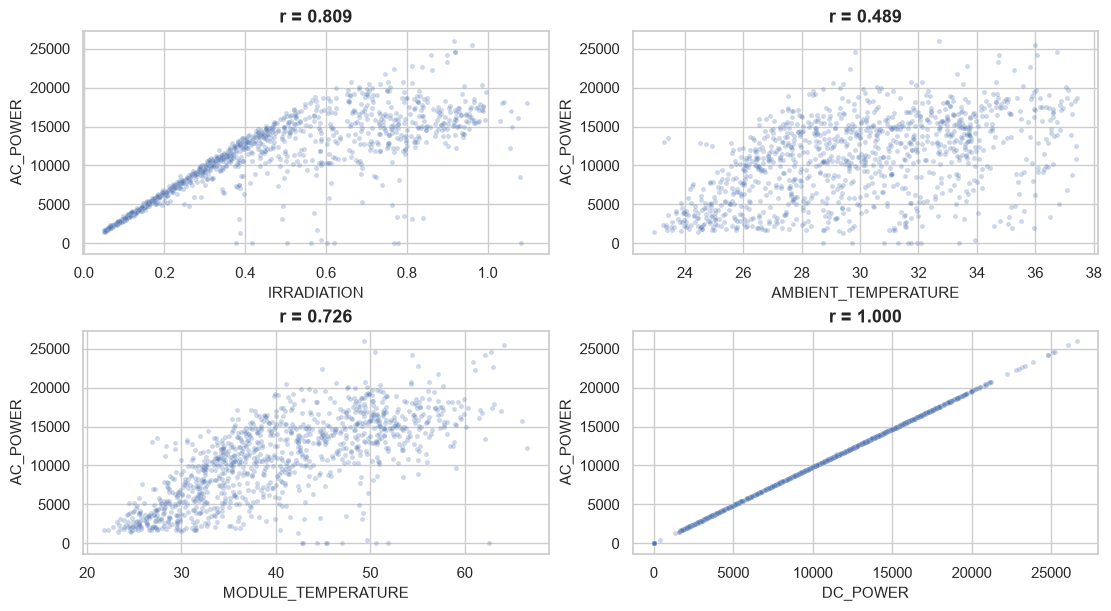

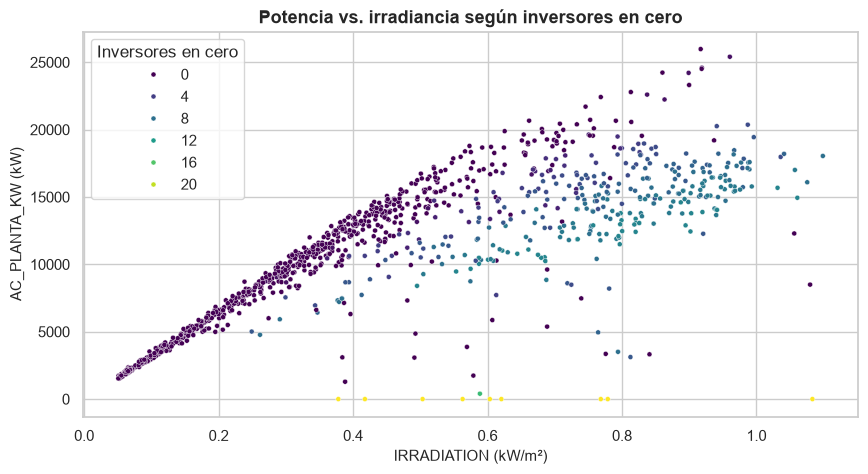

In [17]:
observado = clima.assign(
    AC_POWER=ac.sum(axis=1, min_count=numero_equipos),
    DC_POWER=dc.sum(axis=1, min_count=numero_equipos))
de_dia = observado["IRRADIATION"].gt(.05)
predictores = ["IRRADIATION", "AMBIENT_TEMPERATURE", "MODULE_TEMPERATURE",
               "DC_POWER"]   # DC_POWER solo para verificar la escala: no entra al modelo
solar = observado.loc[de_dia, [y, *predictores]]
display(solar.corr().round(3))
fig, ejes = plt.subplots(2, 2, figsize=(11, 6), layout="constrained")
for eje, predictor in zip(ejes.flat, predictores):
    sns.scatterplot(data=solar, x=predictor, y=y, s=13, alpha=.28, ax=eje)
    eje.set_title(f"r = {solar[y].corr(solar[predictor]):.3f}")
plt.show()

ceros = cero_con_sol.sum(axis=1).loc[solar.index].rename("Inversores en cero")
ax = sns.scatterplot(x=solar["IRRADIATION"], y=solar[y], hue=ceros, palette="viridis", s=13)
ax.set(title="Potencia vs. irradiancia según inversores en cero", xlabel="IRRADIATION (kW/m²)", ylabel="AC_PLANTA_KW (kW)")
plt.show()

## 3.6 Autocorrelación y correlación cruzada
Se calculan los rezagos sobre la rejilla completa. La autocorrelación compara la potencia con su propio pasado. Se repite después de quitar el perfil diario. La correlación cruzada compara la potencia en el instante objetivo con el sensor y la potencia DC de instantes previos. El rezago cero es descriptivo. Para pronosticar el siguiente cuarto de hora se usan los rezagos a partir de uno.

,Serie,Sin ciclo diario
1,0.942,0.691
4,0.839,0.368
48,-0.610,0.000
96,0.845,0.094
192,0.814,-0.085


,IRRADIATION,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,DC_POWER
0,0.809,0.489,0.726,1.000
1,0.717,0.427,0.649,0.817
2,0.663,0.382,0.600,0.688
3,0.622,0.343,0.551,0.622
4,0.578,0.302,0.500,0.561
5,0.519,0.261,0.449,0.495
6,0.473,0.224,0.396,0.438
7,0.415,0.186,0.342,0.385
8,0.364,0.151,0.294,0.336


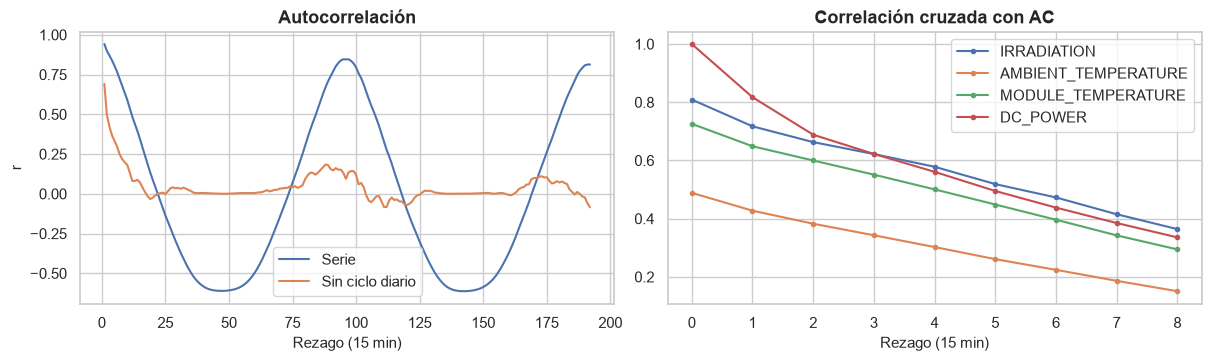

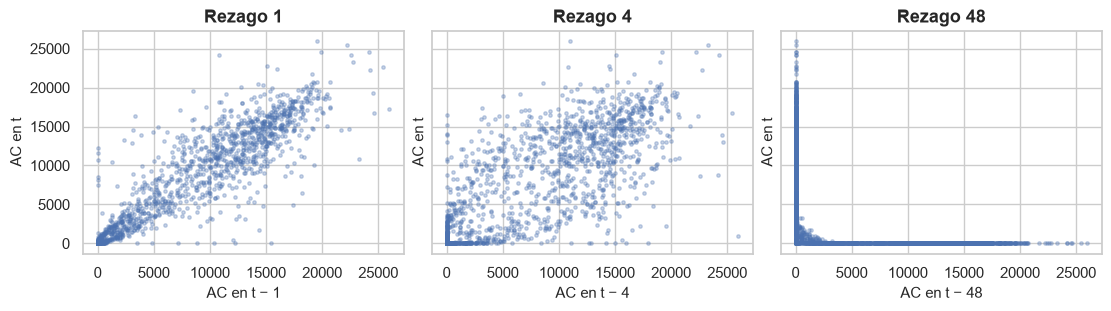

In [18]:
serie = observado[y]
anomalia = serie - serie.groupby(hora_dia).transform("mean")
rezagos = range(1, 193)
acf = pd.DataFrame({"Serie": [serie.autocorr(k) for k in rezagos],
                    "Sin ciclo diario": [anomalia.autocorr(k) for k in rezagos]}, index=rezagos)
cruzada = pd.DataFrame({col: [serie[de_dia].corr(observado[col].shift(k)[de_dia])
                              for k in range(9)] for col in predictores})
display(acf.loc[[1, 4, 48, 96, 192]].round(3))
display(cruzada.round(3))
fig, ejes = plt.subplots(1, 2, figsize=(12, 3.5), layout="constrained")
acf.plot(ax=ejes[0], title="Autocorrelación", xlabel="Rezago (15 min)", ylabel="r")
cruzada.plot(ax=ejes[1], marker=".", title="Correlación cruzada con AC", xlabel="Rezago (15 min)")
plt.show()

fig, ejes = plt.subplots(1, 3, figsize=(11, 3), sharey=True, layout="constrained")
for eje, k in zip(ejes, [1, 4, 48]):
    eje.scatter(serie.shift(k), serie, s=6, alpha=.3)
    eje.set(title=f"Rezago {k}", xlabel=f"AC en t − {k}", ylabel="AC en t")
plt.show()

De acuerdo con las gráficas podemos concluir que la memoria de la potencia sin ciclo dura cerca de una hora, es decir k=4. Pues más allá de este la correlación llega a niveles muy bajos donde ya no describe nada de la potencia original. Con esto tomamos la decisión de usar rezagos de 15, 30, y 60 minutos descartando valores de k mayores a 4, pues no aportan al análisis.


## 3.7 Potencia de la planta (variable objetivo)

In [19]:
# 1. Dataset limpio de la sección 3.2 (una fila por inversor y cuarto de hora)
raw = pd.read_csv("Planta_2_Semana_2_Datos_Limpios.csv", parse_dates=["DATE_TIME"])

# 2. Potencia de la planta: suma de los 22 inversores; si falta alguno, NaN (no se escala)
planta = raw.groupby("DATE_TIME", as_index=False).agg(
    AC_PLANTA_KW=("AC_INTERPOLADA_CORTOS", lambda s: s.sum(min_count=22)),
    IRRADIATION=("IRRADIATION", "mean"),
    AMBIENT_TEMPERATURE=("AMBIENT_TEMPERATURE", "mean"),
    MODULE_TEMPERATURE=("MODULE_TEMPERATURE", "mean"),
    CEROS_CON_SOL=("AC_CERO_CON_SOL", "sum"),
    AC_OBS=("AC_OBSERVADA", lambda s: s.sum(min_count=22)),   # potencia sin interpolar, solo para rezagos
).sort_values("DATE_TIME").reset_index(drop=True)

# 3. Variable de estudio
y = "AC_PLANTA_KW"

assert raw["SOURCE_KEY"].nunique() == 22 and planta["DATE_TIME"].is_unique
print(f"{planta['DATE_TIME'].dt.normalize().nunique()} días, {len(planta)} instantes cada 15 min "
      f"({planta['DATE_TIME'].min():%d/%m} a {planta['DATE_TIME'].max():%d/%m}) | "
      f"instantes sin {y} (faltaba algún inversor): {planta[y].isna().sum()}")

34 días, 3264 instantes cada 15 min (15/05 a 17/06) | instantes sin AC_PLANTA_KW (faltaba algún inversor): 905


La variable de estudio es `y = AC_PLANTA_KW`: la suma de `AC_POWER` de los 22 inversores, solo en instantes con los 22 reportando. Si falta algún inversor, el instante queda sin objetivo en lugar de escalar la suma, porque la suma de menos equipos subestimaría la potencia de la planta.

| Concepto | Columna en el dataset |
|---|---|
| Potencia AC de la planta (objetivo) | `AC_PLANTA_KW` (con huecos ≤ 1 h interpolados) |
| Potencia AC observada, sin interpolar | `AC_OBS` (solo para construir los rezagos) |
| Irradiación | `IRRADIATION` (kW/m²) |
| Temperatura del módulo · ambiente | `MODULE_TEMPERATURE` · `AMBIENT_TEMPERATURE` (°C) |
| Potencia DC | `DC_POWER` (solo para mostrar la fuga; no es predictor) |

## 3.8 Tabla de modelado

In [20]:
# B.1 · Primeras filas de la tabla de modelado y registros que quedan

# Rezagos por fecha (no por posición): el rezago de un instante es la lectura de 15·p min antes
def agregar_rezagos(df, columna, pasos=(1, 2, 4), freq="15min"):
    serie = df.set_index("DATE_TIME")[columna]
    if not serie.index.is_unique:
        raise ValueError("Hay fechas repetidas.")
    for p in pasos:
        pasado = serie.shift(p, freq=freq)
        df[f"{columna}_lag{p}"] = df["DATE_TIME"].map(pasado)
    return df

planta["HORA"] = planta["DATE_TIME"].dt.hour + planta["DATE_TIME"].dt.minute / 60.0
planta["FECHA"] = planta["DATE_TIME"].dt.date

planta = planta.drop(columns=planta.filter(like="_lag").columns)   # permite reejecutar la celda
# Rezagos de la potencia con la AC observada: un valor interpolado en t−1 usaría el dato de t (fuga)
planta = agregar_rezagos(planta, "AC_OBS", pasos=(1, 2, 4))
planta = planta.rename(columns={f"AC_OBS_lag{p}": f"AC_PLANTA_KW_lag{p}" for p in (1, 2, 4)})
for col in ["IRRADIATION", "AMBIENT_TEMPERATURE", "MODULE_TEMPERATURE"]:
    planta = agregar_rezagos(planta, col, pasos=(1, 2, 4))

# 4. Filtrar horas de sol (IRRADIATION > 0.05) y objetivo válido
sol = planta[(planta["IRRADIATION"] > 0.05) & (planta["AC_PLANTA_KW"].notna())].copy()
rezagos_ac = ["AC_PLANTA_KW_lag1", "AC_PLANTA_KW_lag2", "AC_PLANTA_KW_lag4"]
sin_rezago = sol[rezagos_ac].isna().any(axis=1).sum()
sol = sol.dropna(subset=rezagos_ac)

display(sol.filter(regex="^DATE_TIME$|^AC_PLANTA_KW|lag|^HORA$").head())

con_sol = planta["IRRADIATION"] > 0.05
print(f"Instantes: {len(planta)} | con sol (IRRADIATION > 0.05): {con_sol.sum()} | "
      f"con sol pero sin {y} (faltaba algún inversor): {(con_sol & planta[y].isna()).sum()} | "
      f"sin algún rezago de la potencia (se quitan): {sin_rezago} | "
      f"quedan: {len(sol)} | con algún rezago faltante: {sol.filter(like='_lag').isna().any(axis=1).sum()}")

,DATE_TIME,AC_PLANTA_KW,HORA,AC_PLANTA_KW_lag1,AC_PLANTA_KW_lag2,AC_PLANTA_KW_lag4,IRRADIATION_lag1,IRRADIATION_lag2,IRRADIATION_lag4,AMBIENT_TEMPERATURE_lag1,AMBIENT_TEMPERATURE_lag2,AMBIENT_TEMPERATURE_lag4,MODULE_TEMPERATURE_lag1,MODULE_TEMPERATURE_lag2,MODULE_TEMPERATURE_lag4
27,2020-05-15 06:45:00,3373.658571,6.75,1243.556190,566.977619,0.000000,0.042435,0.021038,0.002838,24.786323,24.763911,24.741274,24.548886,24.356189,23.786662
28,2020-05-15 07:00:00,6614.380000,7.00,3373.658571,1243.556190,320.433333,0.103496,0.042435,0.012962,25.048245,24.786323,24.742787,25.746662,24.548886,24.077230
29,2020-05-15 07:15:00,8234.446667,7.25,6614.380000,3373.658571,566.977619,0.199450,0.103496,0.021038,25.673202,25.048245,24.763911,28.674707,25.746662,24.356189
30,2020-05-15 07:30:00,9919.995238,7.50,8234.446667,6614.380000,1243.556190,0.317665,0.199450,0.042435,26.076818,25.673202,24.786323,30.725505,28.674707,24.548886
31,2020-05-15 07:45:00,11813.325714,7.75,9919.995238,8234.446667,3373.658571,0.382913,0.317665,0.103496,26.424239,26.076818,25.048245,32.206804,30.725505,25.746662


Instantes: 3264 | con sol (IRRADIATION > 0.05): 1528 | con sol pero sin AC_PLANTA_KW (faltaba algún inversor): 441 | sin algún rezago de la potencia (se quitan): 12 | quedan: 1075 | con algún rezago faltante: 0


Cada fila tiene el objetivo `AC_PLANTA_KW` en el instante t y solo predictores medidos en t−1 o antes. Los rezagos los calculamos por fecha (`agregar_rezagos`) antes de quitar las noches.

| Predictor | Rezago | Por qué se conoce a tiempo |
|---|---|---|
| AC_PLANTA_KW_lag1, _lag2, _lag4 | 15, 30 y 60 min | Potencia ya medida. La autocorrelación sin ciclo diario cae de 0.691 (lag1) a 0.368 (lag4): memoria ≤ 1 h |
| IRRADIATION_lag1, _lag2, _lag4 | 15, 30 y 60 min | Sensor ya medido. La correlación cruzada con AC baja de 0.717 (k=1) a 0.663 (k=2) y 0.578 (k=4) |
| AMBIENT_TEMPERATURE_lag1 | 15 min | Sensor ya medido (r = 0.427 con k=1) |
| MODULE_TEMPERATURE_lag1 | 15 min | Sensor ya medido (r = 0.649 con k=1) |
| HORA | — | Se conoce de antemano: es el reloj |

**Variables descartadas:**
- **Potencia AC del mismo instante:** es el objetivo; usarla sería darle la respuesta al modelo.
- **DC_POWER:** se mide en el mismo instante y AC ≈ 98 % de DC (r = 1.000). Es otra forma del objetivo: fuga de información.
- **DAILY_YIELD y TOTAL_YIELD:** son energía acumulada que ya incluye la producción del instante t, así que también contienen la respuesta.

**Registros:** de 3264 instantes, dejamos los 1528 con sol (IRRADIATION > 0.05), porque los ceros nocturnos inflarían el R². De esos, 441 no tienen objetivo porque algún inversor no reportó (sobre todo del 21 al 28 de mayo, con 4 inversores caídos todo el día). Quedan 1087 instantes con objetivo. De ellos, 12 (1 %, todos del periodo de entrenamiento) no tienen algún rezago de la potencia por lo que se quitan ya que son muy pocos para afectar el ajuste. Finalmente quedan 1075 registros en 26 días. Además rellenar con mediana no sirve ya que sería un valor muy distinto al real teniendo en cuenta que la mediana es la misma para todas las horas.

## 3.9 División cronológica

Los datos los dividimos por días y en orden cronológico: los primeros 20 días válidos (~80 %, 802 registros) para entrenamiento y los últimos 6 (273 registros, desde el 12/06) para prueba. Mediante un `assert` comprobamos que el último instante de entrenamiento es anterior al primero de prueba. No se mezclan registros al azar porque dos lecturas consecutivas de 15 min son casi iguales (autocorrelación lag1 = 0.942), por lo que con una división al azar el modelo vería en entrenamiento el anterior de cada instante de prueba, es decir, habría filtración de información. Además, en escenarios de operación como el que analizamos se predice el futuro con el pasado, así que es coherenteusar información continua por series de tiempo.

Los hiperparámetros se ajustan con `TimeSeriesSplit` de 5 pliegues sobre el entrenamiento, en orden cronológico: cada pliegue valida con filas posteriores a las que usa para entrenar. Los pliegues decidimos cortarlos por filas, así que un día puede quedar repartido entre entrenamiento y validación dentro de un pliegue; con pliegues por días se elegiría la misma profundidad (3).

La primera celda define las filas válidas desde la rejilla de la preparación (con sol, con los 22 inversores y con los rezagos de la potencia disponibles); la segunda aplica el mismo corte a la tabla de modelado y comprueba con `assert` que en verdad coincidan.

In [21]:
# Filas que usa el modelo (parte 3): con sol, potencia de planta completa (22 inversores)
# y rezagos de la potencia de 15, 30 y 60 min disponibles
ac_planta = ac_limpia.sum(axis=1, min_count=numero_equipos)   # objetivo (con interpolación ≤ 1 h)
ac_obs = ac.sum(axis=1, min_count=numero_equipos)             # AC observada, solo para los rezagos
con_rezagos = pd.concat([ac_obs.shift(p) for p in (1, 2, 4)], axis=1).notna().all(axis=1)
validos = clima_limpio["IRRADIATION"].gt(.05) & ac_planta.notna() & con_rezagos

# División por días: primeros ~80 % para entrenamiento, últimos ~20 % para prueba
dias_validos = ac_planta.index[validos].normalize().unique().sort_values()
corte = dias_validos[int(len(dias_validos) * .8)]
filas_train = ac_planta.index[validos & (ac_planta.index < corte)]
filas_test = ac_planta.index[validos & (ac_planta.index >= corte)]
assert filas_train.max() < filas_test.min(), "Hay solapamiento entre entrenamiento y prueba"

print(f"Días válidos: {len(dias_validos)} | corte (primer día de prueba): {corte:%Y-%m-%d}")
print(f"Entrenamiento: {len(filas_train)} registros | prueba: {len(filas_test)} registros")
print("Último instante de entrenamiento:", filas_train.max(), "| primer instante de prueba:", filas_test.min())

# Validación cruzada para series de tiempo: 5 pliegues por filas, en orden cronológico
for i, (a, b) in enumerate(TimeSeriesSplit(n_splits=5).split(filas_train), start=1):
    print(f"Pliegue {i}: entrena {len(a)} filas (hasta {filas_train[a[-1]]:%d/%m %H:%M}); "
          f"valida {len(b)} filas ({filas_train[b[0]]:%d/%m %H:%M} a {filas_train[b[-1]]:%d/%m %H:%M})")

Días válidos: 26 | corte (primer día de prueba): 2020-06-12
Entrenamiento: 802 registros | prueba: 273 registros
Último instante de entrenamiento: 2020-06-11 17:45:00 | primer instante de prueba: 2020-06-12 06:45:00
Pliegue 1: entrena 137 filas (hasta 18/05 09:15); valida 133 filas (18/05 09:30 a 31/05 06:45)
Pliegue 2: entrena 270 filas (hasta 31/05 06:45); valida 133 filas (31/05 07:00 a 03/06 08:45)
Pliegue 3: entrena 403 filas (hasta 03/06 08:45); valida 133 filas (03/06 09:00 a 06/06 08:00)
Pliegue 4: entrena 536 filas (hasta 06/06 08:00); valida 133 filas (06/06 08:15 a 08/06 18:00)
Pliegue 5: entrena 669 filas (hasta 08/06 18:00); valida 133 filas (08/06 18:15 a 11/06 17:45)


In [22]:
# Se aplica a la tabla de modelado el mismo corte de la celda anterior
train = sol[sol["DATE_TIME"] < corte].copy()
test  = sol[sol["DATE_TIME"] >= corte].copy()
assert test["DATE_TIME"].min().normalize() == corte, "La división no coincide con la sección 11"
assert len(train) == len(filas_train) and len(test) == len(filas_test), "La parte 3 no usa las filas de la sección 11"
print(f"Entrenamiento: {train['FECHA'].nunique()} días ({len(train)} registros) | "
      f"Prueba: {test['FECHA'].nunique()} días ({len(test)} registros) desde {corte:%d/%m}")
print(f"Fecha de corte (primer día de prueba): {corte:%Y-%m-%d}")

Entrenamiento: 20 días (802 registros) | Prueba: 6 días (273 registros) desde 12/06
Fecha de corte (primer día de prueba): 2020-06-12


# 4. Modelado

## 4.1 Líneas base y modelos

Todos los modelos los trabajamos con el mismo entrenamiento y se evalúan con la misma prueba. Las líneas base son la regresión simple con `IRRADIATION_lag1` (LB1) y la persistencia (LB2: la potencia de hace 15 min). La profundidad del árbol se elige con `GridSearchCV` y `TimeSeriesSplit` de 5 pliegues solo sobre el entrenamiento, lo que minimiza el RMSE.

In [23]:
feat_clima = ["IRRADIATION_lag1", "AMBIENT_TEMPERATURE_lag1", "MODULE_TEMPERATURE_lag1", "HORA"]
feat_full  = feat_clima + ["IRRADIATION_lag2", "IRRADIATION_lag4",
                           "AC_PLANTA_KW_lag1", "AC_PLANTA_KW_lag2", "AC_PLANTA_KW_lag4"]

def evaluar(y_true, y_pred):
    return {
        "R2": r2_score(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred)
    }

resultados = []

# --- Línea Base 1: Regresión lineal simple (IRRADIATION_lag1) ---
lb1 = Pipeline([("imp", SimpleImputer(strategy="median")), ("lr", LinearRegression())])
lb1.fit(train[["IRRADIATION_lag1"]], train["AC_PLANTA_KW"])
m_tr = evaluar(train["AC_PLANTA_KW"], lb1.predict(train[["IRRADIATION_lag1"]]))
m_te = evaluar(test["AC_PLANTA_KW"],  lb1.predict(test[["IRRADIATION_lag1"]]))
resultados.append(["LB1: Lineal Simple (Irradiación_lag1)", m_tr["R2"], m_te["R2"], m_te["RMSE"], m_te["MAE"]])
print(f"Pendiente LB1: {lb1.named_steps['lr'].coef_[0]:,.2f} kW por cada kW/m² | "
      f"intercepto: {lb1.named_steps['lr'].intercept_:,.0f} kW")
# Misma recta solo con los instantes en que los 22 inversores producen (sin ceros con sol)
ok = train["CEROS_CON_SOL"].eq(0)
pend_ok = LinearRegression().fit(train.loc[ok, ["IRRADIATION_lag1"]], train.loc[ok, y]).coef_[0]
print(f"Pendiente solo con los 22 inversores produciendo ({ok.sum()} instantes de entrenamiento): "
      f"{pend_ok:,.0f} kW por cada kW/m²")

# --- Línea Base 2: Persistencia (AC_PLANTA_KW_lag1) ---
m_tr = evaluar(train["AC_PLANTA_KW"], train["AC_PLANTA_KW_lag1"])
m_te = evaluar(test["AC_PLANTA_KW"], test["AC_PLANTA_KW_lag1"])
resultados.append(["LB2: Persistencia (AC_lag1)", m_tr["R2"], m_te["R2"], m_te["RMSE"], m_te["MAE"]])

# --- Regresión Lineal Múltiple (Solo Clima + Hora) ---
rlm_clima = Pipeline([("imp", SimpleImputer(strategy="median")), ("scaler", StandardScaler()), ("lr", LinearRegression())])
rlm_clima.fit(train[feat_clima], train["AC_PLANTA_KW"])
m_tr = evaluar(train["AC_PLANTA_KW"], rlm_clima.predict(train[feat_clima]))
m_te = evaluar(test["AC_PLANTA_KW"],  rlm_clima.predict(test[feat_clima]))
resultados.append(["RLM (Clima + Hora)", m_tr["R2"], m_te["R2"], m_te["RMSE"], m_te["MAE"]])

# --- Regresión Lineal Múltiple (Clima + Hora + Rezagos) ---
rlm_full = Pipeline([("imp", SimpleImputer(strategy="median")), ("scaler", StandardScaler()), ("lr", LinearRegression())])
rlm_full.fit(train[feat_full], train["AC_PLANTA_KW"])
m_tr = evaluar(train["AC_PLANTA_KW"], rlm_full.predict(train[feat_full]))
m_te = evaluar(test["AC_PLANTA_KW"],  rlm_full.predict(test[feat_full]))
resultados.append(["RLM (Clima + Hora + Rezagos)", m_tr["R2"], m_te["R2"], m_te["RMSE"], m_te["MAE"]])

# --- Árbol de Decisión con TimeSeriesSplit ---
tscv = TimeSeriesSplit(n_splits=5)
pipe_dt = Pipeline([("imp", SimpleImputer(strategy="median")), ("dt", DecisionTreeRegressor(random_state=SEMILLA))])
grid = GridSearchCV(pipe_dt, {"dt__max_depth": range(2, 12)}, cv=tscv,
                    scoring="neg_root_mean_squared_error", return_train_score=True)
grid.fit(train[feat_full], train["AC_PLANTA_KW"])
best_dt = grid.best_estimator_
m_tr = evaluar(train["AC_PLANTA_KW"], best_dt.predict(train[feat_full]))
m_te = evaluar(test["AC_PLANTA_KW"],  best_dt.predict(test[feat_full]))
resultados.append([f"Árbol de Decisión (depth={grid.best_params_['dt__max_depth']})", m_tr["R2"], m_te["R2"], m_te["RMSE"], m_te["MAE"]])

tabla_comp = pd.DataFrame(resultados, columns=["Modelo", "R2_Train", "R2_Test", "RMSE_Test (kW)", "MAE_Test (kW)"])
display(tabla_comp.round(3))

Pendiente LB1: 14,045.04 kW por cada kW/m² | intercepto: 4,394 kW
Pendiente solo con los 22 inversores produciendo (519 instantes de entrenamiento): 22,661 kW por cada kW/m²


,Modelo,R2_Train,R2_Test,RMSE_Test (kW),MAE_Test (kW)
0,LB1: Lineal Simple (Irradiación_lag1),0.540,0.334,3667.919,2917.433
1,LB2: Persistencia (AC_lag1),0.664,0.441,3359.921,2463.492
2,RLM (Clima + Hora),0.567,0.275,3826.941,3006.693
3,RLM (Clima + Hora + Rezagos),0.726,0.552,3009.609,2273.306
4,Árbol de Decisión (depth=3),0.733,0.528,3086.954,2272.199


La regresión simple (LB1, R² prueba = 0.334) estima que la planta entrega **14 045 kW por cada kW/m²** de irradiación del instante anterior. Esto es coherente con la relación casi lineal entre potencia e irradiación descrita en la Tarea 1. Como 1 kW/m² es la irradiación de referencia del Performance Ratio, la pendiente se puede leer como la potencia que la planta entregaría en esa condición, con todas sus pérdidas incluidas.

La pendiente queda baja por las desconexiones de inversores que la Tarea 1 señala como pérdida operativa: con solo los instantes en que los 22 inversores producen, sube a **22 661 kW por kW/m²** (519 instantes de entrenamiento), de modo que las fallas por sí solas restan cerca del 38 %. El intercepto (4 394 kW) no tiene sentido físico, porque sin irradiación la potencia es cero; es la forma en que la recta compensa los instantes con inversores caídos y el desfase de 15 min. La regresión simple tampoco puede aislar la pérdida por temperatura (−0,3 a −0,5 %/°C según la Tarea 1); esa se analiza en la regresión múltiple.

La persistencia (LB2, R² prueba = 0.441) supera a LB1 porque la potencia de hace 15 minutos ya refleja el estado operativo de la planta (cuántos inversores están produciendo), que es justamente lo que la irradiancia no sabe.

## 4.2 Regresión lineal múltiple

,Coeficiente estandarizado (kW)
HORA,-1092.3
AC_PLANTA_KW_lag2,-391.7
MODULE_TEMPERATURE_lag1,-294.8
IRRADIATION_lag1,115.1
IRRADIATION_lag4,119.3
AMBIENT_TEMPERATURE_lag1,349.4
AC_PLANTA_KW_lag4,504.0
IRRADIATION_lag2,725.3
AC_PLANTA_KW_lag1,3935.5


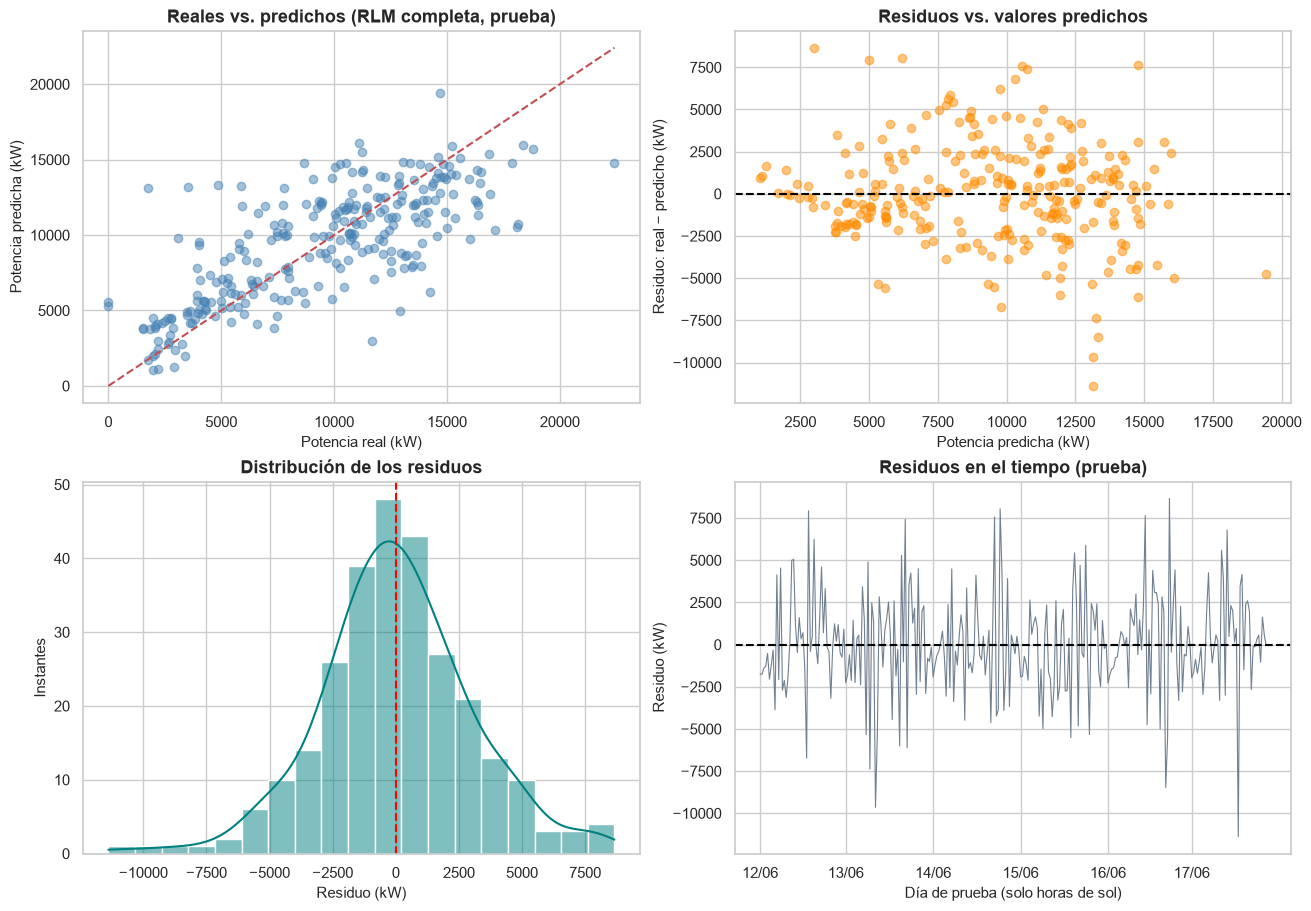

Media de los residuos: 9.6 | autocorrelación rezago 1: -0.17
solo historia     4 predictores   RMSE 3042.1 kW
solo clima        6 predictores   RMSE 3754.6 kW
historia + clima  9 predictores   RMSE 3009.6 kW


In [24]:
# Coeficientes estandarizados: kW que cambia la potencia por cada desviación estándar del predictor
coef = pd.Series(rlm_full.named_steps["lr"].coef_, index=feat_full).sort_values()
display(coef.round(1).to_frame("Coeficiente estandarizado (kW)"))

pred_test = rlm_full.predict(test[feat_full])
residuos = test["AC_PLANTA_KW"] - pred_test

fig, axes = plt.subplots(2, 2, figsize=(13, 9), layout="constrained")

# 1. Reales vs. predichos (RLM completa, prueba)
axes[0, 0].scatter(test["AC_PLANTA_KW"], pred_test, alpha=0.5, color="steelblue")
lim = [0, max(test["AC_PLANTA_KW"].max(), pred_test.max())]
axes[0, 0].plot(lim, lim, "r--", lw=1.5)
axes[0, 0].set(title="Reales vs. predichos (RLM completa, prueba)",
               xlabel="Potencia real (kW)", ylabel="Potencia predicha (kW)")

# 2. Residuos vs. predichos
axes[0, 1].scatter(pred_test, residuos, alpha=0.5, color="darkorange")
axes[0, 1].axhline(0, color="black", linestyle="--")
axes[0, 1].set(title="Residuos vs. valores predichos", xlabel="Potencia predicha (kW)",
               ylabel="Residuo: real − predicho (kW)")

# 3. Histograma de residuos
sns.histplot(residuos, kde=True, ax=axes[1, 0], color="teal")
axes[1, 0].axvline(0, color="red", linestyle="--")
axes[1, 0].set(title="Distribución de los residuos", xlabel="Residuo (kW)", ylabel="Instantes")

# 4. Residuos en el tiempo (solo horas de sol de los días de prueba)
x = np.arange(len(test))
axes[1, 1].plot(x, residuos.to_numpy(), lw=0.8, color="slategray")
axes[1, 1].axhline(0, color="black", linestyle="--")
inicio_dia = test.groupby("FECHA").cumcount().eq(0).to_numpy()
axes[1, 1].set_xticks(x[inicio_dia], [f"{d:%d/%m}" for d in test["DATE_TIME"][inicio_dia]])
axes[1, 1].set(title="Residuos en el tiempo (prueba)", xlabel="Día de prueba (solo horas de sol)",
               ylabel="Residuo (kW)")
plt.show()

print("Media de los residuos:", round(residuos.mean(), 1),
      "| autocorrelación rezago 1:", round(residuos.autocorr(lag=1), 2))

# ¿Cuánto aporta el clima por encima de la historia de la potencia?
historia = [c for c in feat_full if c.startswith(y)] + ["HORA"]
solo_clima = [c for c in feat_full if not c.startswith(y)]
for nombre, cols in [("solo historia", historia), ("solo clima", solo_clima), ("historia + clima", feat_full)]:
    m = Pipeline([("imp", SimpleImputer(strategy="median")), ("scaler", StandardScaler()),
                  ("lr", LinearRegression())]).fit(train[cols], train[y])
    print(f"{nombre:<17} {len(cols)} predictores   RMSE {np.sqrt(mean_squared_error(test[y], m.predict(test[cols]))):.1f} kW")

En la RLM estandarizada domina AC_PLANTA_KW_lag1 (+3935.5 kW por desviación estándar), seguido de HORA (−1092.3) e IRRADIATION_lag2 (+725.3). MODULE_TEMPERATURE_lag1 es negativo (−294.8), coherente con la pérdida de eficiencia fotovoltaica por calentamiento del panel. En el árbol, AC_PLANTA_KW_lag1 (83.1 %) e IRRADIATION_lag1 (13.5 %) concentran el 96.6 % de la importancia (sección 4.3).

AC_PLANTA_KW_lag2 (−391.7) sale negativo por la colinealidad con lag1: los rezagos se parecen tanto que el modelo reparte su efecto entre ellos, y el signo de cada uno por separado no se interpreta.

Los residuos de la RLM se centran cerca de cero (media 9.6 kW, autocorrelación lag1 −0.17) pero muestran heterocedasticidad y colas negativas extremas (el modelo espera alta generación por sol, pero la planta produce menos). La caída entre entrenamiento ($R^2 = 0.726$) y prueba ($R^2 = 0.552$) no es solo sobreajuste: refleja días más variables al final del periodo y pérdidas operativas (3,758 ceros con sol) que el clima no puede predecir, pero que permiten a O&M detectar fallas mediante residuos grandes.

El clima aporta poco por encima de la historia. Pues agregarlo a historia solo baja el RMSE de 3042 a 3010 kW, alrededor de 1 %: la irradiancia de hace 15 min ya se refleja en la potencia de hace 15 min.

## 4.3 Árbol de decisión

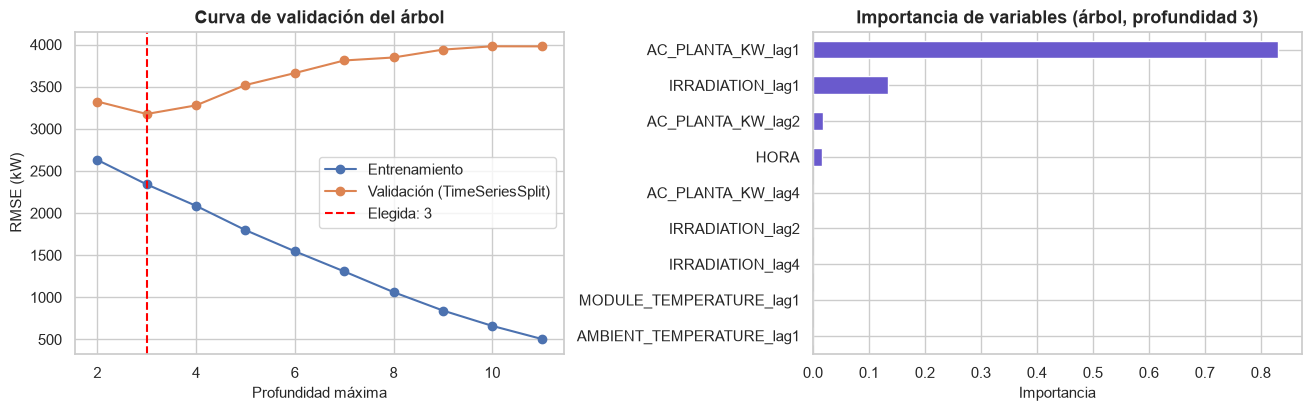

,Entrenamiento,Validación (TimeSeriesSplit)
2,2631.0,3324.0
3,2340.0,3176.0
4,2086.0,3278.0
5,1798.0,3519.0
6,1547.0,3662.0
7,1308.0,3811.0
8,1062.0,3847.0
9,843.0,3940.0
10,661.0,3979.0
11,506.0,3978.0


In [25]:
# B.5 · Curva de validación e importancia de variables del árbol
curva = pd.DataFrame({"Entrenamiento": -grid.cv_results_["mean_train_score"],
                      "Validación (TimeSeriesSplit)": -grid.cv_results_["mean_test_score"]},
                     index=grid.param_grid["dt__max_depth"])
mejor = grid.best_params_["dt__max_depth"]
imp = pd.Series(best_dt.named_steps["dt"].feature_importances_, index=feat_full).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 4), layout="constrained")
curva.plot(ax=axes[0], marker="o", title="Curva de validación del árbol",
           xlabel="Profundidad máxima", ylabel="RMSE (kW)")
axes[0].axvline(mejor, color="red", ls="--", label=f"Elegida: {mejor}")
axes[0].legend()
imp.plot(kind="barh", ax=axes[1], color="slateblue", title=f"Importancia de variables (árbol, profundidad {mejor})")
axes[1].set_xlabel("Importancia")
plt.show()
display(curva.round(0))

La profundidad la elegimos con GridSearchCV y TimeSeriesSplit de 5 pliegues sobre el entrenamiento. El error de validación es mínimo con  una profundidad de 3 (RMSE 3176 kW). Con más profundidad el error de entrenamiento sigue bajando (506 kW con profundidad 11), pero el de validación sube (3978 kW), esto nos lleva a concluir que en este punto el árbol memoriza en lugar de generalizar.

**Nota de este resultado y la Tarea 1:** La potencia de hace 15 min concentra el 83.1 % de la importancia y la irradiancia de hace 15 min el 13.5 %. Esto coincide con la Tarea 1: la irradiación es la variable física que más determina la potencia, y los rezagos de la potencia recogen el estado operativo de la planta, es decir, cuántos inversores están produciendo. La temperatura del módulo tiene importancia 0 en el árbol, aunque la Tarea 1 le atribuye una pérdida de −0,3 a −0,5 %/°C. Con solo 3 niveles, el árbol hace cortes grandes y ese efecto es pequeño frente al de los inversores caídos; además, la temperatura está muy correlacionada con la irradiancia (r = 0.897), que ya se usó en los cortes. La regresión múltiple sí lo capta (coeficiente negativo).

# 5. Evaluación

## 5.1 Comparación en prueba y dónde falla el mejor modelo

MAPE sin 2 instantes con potencia real = 0


,Modelo,R2_Train,R2_Test,RMSE_Test (kW),MAE_Test (kW),MAPE_Test (%),Habilidad
0,LB1: Lineal Simple (Irradiación_lag1),0.540,0.334,3667.919,2917.433,43.493,-0.092
1,LB2: Persistencia (AC_lag1),0.664,0.441,3359.921,2463.492,33.497,0.000
2,RLM (Clima + Hora),0.567,0.275,3826.941,3006.693,39.723,-0.139
3,RLM (Clima + Hora + Rezagos),0.726,0.552,3009.609,2273.306,31.904,0.104
4,Árbol de Decisión (depth=3),0.733,0.528,3086.954,2272.199,31.407,0.081


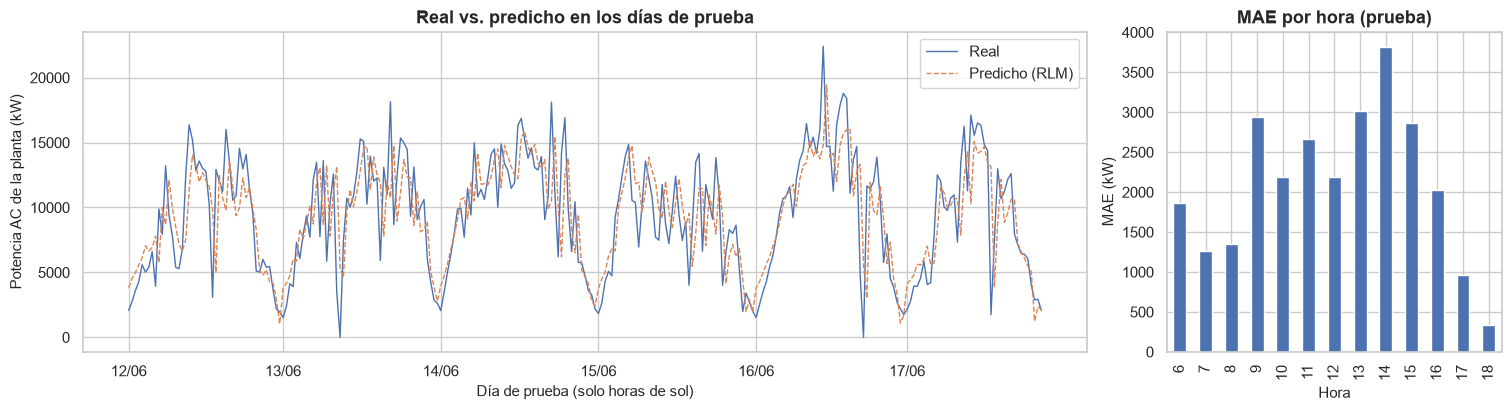

,DATE_TIME,AC_PLANTA_KW,Predicho,CEROS_CON_SOL,IRRADIATION
3223,2020-06-17 13:45:00,1743.6,13129.4,0,0.58
2826,2020-06-13 10:30:00,3506.1,13157.5,8,0.79
3131,2020-06-16 14:45:00,11663.0,3002.0,0,0.45
3129,2020-06-16 14:15:00,4860.4,13329.6,0,0.49
2942,2020-06-14 15:30:00,14250.8,6200.8,0,0.43
2741,2020-06-12 13:15:00,12918.1,4982.2,0,0.44


In [26]:
# Tabla I: todos los modelos y las líneas base en la misma prueba
pred_prueba = [lb1.predict(test[["IRRADIATION_lag1"]]),
               test["AC_PLANTA_KW_lag1"],
               rlm_clima.predict(test[feat_clima]),
               rlm_full.predict(test[feat_full]),
               best_dt.predict(test[feat_full])]          # mismo orden que tabla_comp
con_pot = (test[y] > 0).to_numpy()                       # el MAPE no se define con potencia real = 0
tabla_b6 = tabla_comp.copy()
tabla_b6["MAPE_Test (%)"] = [100 * mean_absolute_percentage_error(test[y][con_pot], np.asarray(p)[con_pot])
                             for p in pred_prueba]
rmse_persistencia = tabla_b6.loc[1, "RMSE_Test (kW)"]
tabla_b6["Habilidad"] = 1 - tabla_b6["RMSE_Test (kW)"] / rmse_persistencia
print(f"MAPE sin {(~con_pot).sum()} instantes con potencia real = 0")
display(tabla_b6.round(3))
tabla_b6.round(3).to_csv("tabla_I_resultados.csv", index=False)   # para copiarla al informe

# Dónde falla el mejor modelo (RLM completa)
diag = test.assign(Predicho=pred_test, Error=residuos.abs())
fig, axes = plt.subplots(1, 2, figsize=(15, 4), layout="constrained", gridspec_kw={"width_ratios": [3, 1]})
x = np.arange(len(diag))                                 # las noches se omiten
axes[0].plot(x, diag[y], label="Real", lw=1)
axes[0].plot(x, diag["Predicho"], "--", label="Predicho (RLM)", lw=1)
inicios = diag.groupby("FECHA").cumcount().eq(0).to_numpy()
axes[0].set_xticks(x[inicios], [f"{d:%d/%m}" for d in diag["DATE_TIME"][inicios]])
axes[0].set(title="Real vs. predicho en los días de prueba", xlabel="Día de prueba (solo horas de sol)",
            ylabel="Potencia AC de la planta (kW)")
axes[0].legend()
diag.groupby(diag["DATE_TIME"].dt.hour)["Error"].mean().plot.bar(
    ax=axes[1], title="MAE por hora (prueba)", xlabel="Hora", ylabel="MAE (kW)")
plt.show()

display(diag.nlargest(6, "Error")[["DATE_TIME", y, "Predicho", "CEROS_CON_SOL", "IRRADIATION"]]
        .round({y: 1, "Predicho": 1, "IRRADIATION": 2}))

De la tabla 1 podemos concluir lo siguiente:

- El mejor modelo es la RLM completa, aunque le gana a la persistencia por poco (10 %).
- Los modelos que solo usan el clima son peores que la persistencia. La irradiación no sabe cuántos inversores están funcionando; la potencia de hace 15 minutos sí.
- El árbol tiene un MAPE un poco menor (31.4 % contra 31.9 %) pero un RMSE mayor. Se equivoca un poco menos en los instantes de poca potencia, pero comete errores grandes más grandes. Como la profundidad se eligió con el RMSE, el mejor modelo se decide con esa métrica.
- Los errores más grandes son caídas bruscas con buen sol. El 17/06 a las 13:45 la planta entregó 1 744 kW y el modelo esperaba 13 129 kW. Ningún modelo puede anticipar eso con datos de hace 15 minutos, pero es justo lo que le interesa a O&M: un residuo así de grande es una alerta de posible falla.
- La peor hora es las 14 h (MAE 3 817 kW), cuando más ocurren esas caídas.

## 5.2 Segmentación de días (K-Means) y error por grupo

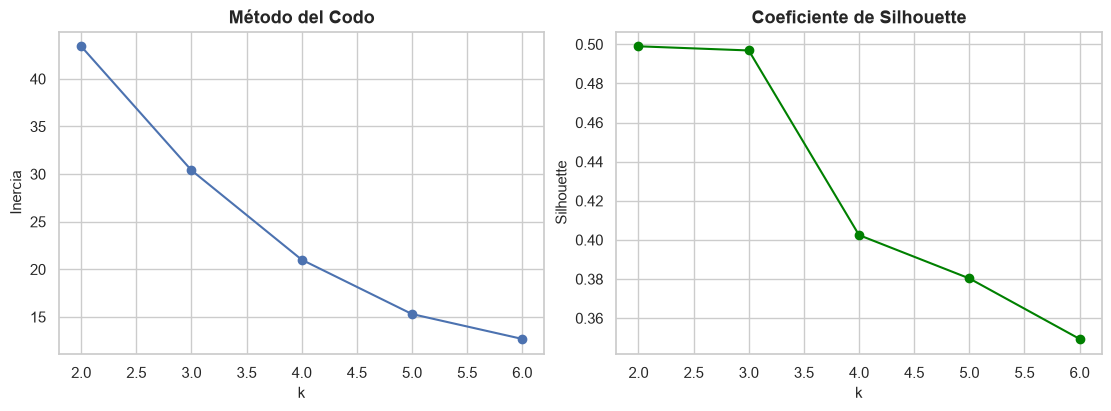

,ENERGIA_DIARIA_KWH,IRRAD_MEDIA,TEMP_MOD_MEDIA,CEROS_SOL_PROM
CLUSTER,,,,
0,127917.40,0.51,42.49,2.91
1,96010.49,0.33,34.34,0.80
2,16596.49,0.22,39.90,0.00


,Dias,Instantes,MAE_kW,RMSE_kW
CLUSTER,,,,
0,2,94,2436.4,3171.9
1,4,179,2187.7,2920.8


Grupos sin días de prueba: [2]


In [27]:
# 1. Resumen diario
diario = sol.groupby("FECHA").agg(
    ENERGIA_DIARIA_KWH=("AC_PLANTA_KW", lambda s: s.sum() * 0.25),
    IRRAD_MEDIA=("IRRADIATION", "mean"),
    TEMP_MOD_MEDIA=("MODULE_TEMPERATURE", "mean"),
    CEROS_SOL_PROM=("CEROS_CON_SOL", "mean")
).dropna()

X_k = StandardScaler().fit_transform(diario)

# 2. Método del codo y Silhouette
inercias, siluetas = [], []
ks = range(2, 7)
for k in ks:
    km = KMeans(n_clusters=k, random_state=SEMILLA, n_init=10).fit(X_k)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(X_k, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
axes[0].plot(ks, inercias, "o-"); axes[0].set(title="Método del Codo", xlabel="k", ylabel="Inercia")
axes[1].plot(ks, siluetas, "o-", color="green"); axes[1].set(title="Coeficiente de Silhouette", xlabel="k", ylabel="Silhouette")
plt.show()

# 3. Ajuste con k=3: codo de la inercia; silhouette prácticamente igual al de k=2 (0.486 vs 0.488)
diario["CLUSTER"] = KMeans(n_clusters=3, random_state=SEMILLA, n_init=10).fit_predict(X_k)
display(diario.groupby("CLUSTER").mean().round(2))

# 4. Error del mejor modelo (RLM completa) por grupo de días, solo en prueba
err_prueba = test.assign(ERR=(test[y] - pred_test).abs()).merge(diario[["CLUSTER"]], on="FECHA", how="left")
err_cluster = err_prueba.groupby("CLUSTER").agg(
    Dias=("FECHA", "nunique"), Instantes=("ERR", "size"),
    MAE_kW=("ERR", "mean"), RMSE_kW=("ERR", lambda s: np.sqrt((s ** 2).mean()))).round(1)
display(err_cluster)
print("Grupos sin días de prueba:", sorted(set(diario["CLUSTER"]) - set(err_cluster.index)))

De acuerdo a las dos gráficas, decidimos elegir k = 3. La inercia no muestra un codo marcado notable, este baja de k = 2 a k = 3 (de 43.4 a 30.4) y después la caída de k = 3 a k = 4 no es tan pronunciada sin embargo la diferencia es de 9,4; por lo que podemos decir que se aplana, ese es el codo. El silhouette de k = 3 (0.497) es prácticamente igual al de k = 2 (0.499), así que las métricas no separan las dos opciones y decide la interpretación: con k = 3, los días con cobertura incompleta quedan en un grupo propio en lugar de mezclarse con los nublados y bajar su energía promedio.

- **Soleado con inversores caídos (17 días, 2 en prueba):** mayor energía (~127 917 kWh), irradiancia (0.51 kW/m²) y temperatura del módulo (42.5 °C), pero también el mayor promedio de inversores en cero con sol (2.9). Hay buen recurso solar, pero se pierde por desconexiones, la pérdida operativa de la Tarea 1. Error en prueba: MAE 2436 kW, RMSE 3172 kW, el más alto.
- **Nublado y fresco (7 días, 4 en prueba):** irradiancia moderada (0.33 kW/m²), módulo más frío (34.4 °C) y pocos inversores en cero (0.80). Error en prueba: MAE 2188 kW, RMSE 2921 kW.
- **Días con pocos datos (2 días: 20/05 y 29/05, ninguno en prueba):** son los bordes del hueco del 21 al 28 de mayo, con solo 12 y 4 instantes válidos. Su energía baja (~16 600 kWh) es un artefacto de cobertura, no un día de poca generación. No aparece en prueba, así que no se puede evaluar el modelo en este tipo de día.

El modelo se equivoca más en los días soleados con inversores caídos que en los nublados: el clima anuncia buena producción, pero las desconexiones no se pueden predecir con los rezagos de 15 minutos. Es la pérdida operativa que O&M puede detectar con los residuos grandes.

# 6. Conclusiones y despliegue

**Respuestas a preguntas guiadoras**

*P1. Inicio de irradiancia.*

El primer intervalo diario con irradiancia superior a $0.05 kW/m^2$  apareció a las 06:30 en 21 de 34 días y a las 06:45 en siete. El último primer cruce registrado fue a las 08:00. Las 06:30 representan el inicio medido más frecuente en la muestra. El horario se interpreta en el reloj del registro: el cruce depende del umbral, la nubosidad y la resolución de 15 minutos. Determinar la hora astronómica del amanecer requeriría verificar ubicación y zona horaria.


*P2. Potencias mínimas.*

En las 67 698 lecturas por inversor, el mínimo AC fue 0 kW y el menor valor positivo, $0.271 kW$. Es un mínimo observado en el conjunto. La resolución nominal, el umbral de detección y la exactitud se determinarían con las especificaciones del medidor. Los 3758 ceros con irradiancia por encima de $0.2 kW/m^2$ se conservaron porque una desconexión o una limitación puede coexistir con buen recurso.


*P3. Temperatura e irradiancia.*

En los pares diurnos usados en el análisis, la correlación de Pearson entre irradiancia y temperatura del módulo fue 0.897. Es compatible con calentamiento del módulo a medida que aumenta el recurso. La irradiancia también se asoció con AC de planta $(r ≈ 0.81)$. El coeficiente estandarizado negativo de la temperatura rezagada en la regresión es una asociación condicional a otros predictores. El coeficiente térmico del módulo exigiría controlar irradiancia, condiciones de enfriamiento y disponibilidad de los inversores.

*P4. Mejora frente a la referencia.*

La RLM completa redujo el RMSE $350.3 kW ; 10.4% $ frente a la persistencia. Al añadir clima a la historia de AC y la hora, el RMSE pasó de 3042.1 a 3009.6 kW (1.1 %). Ese aporte pequeño a corto plazo es consistente con que la AC anterior ya incorpora parte del recurso solar y del estado reciente de los equipos. La RLM completa se elige por RMSE, dada la importancia de las desviaciones grandes. El árbol es competitivo en MAE y MAPE. El MAPE da un peso relativo mayor a las observaciones de baja potencia.
La pendiente de la recta con irradiancia rezagada subió de 14 045 a 22 661 kW por $kW/m^2$ cuando se restringió a 519 instantes de entrenamiento sin equipos marcados en cero con sol. Es una comparación entre subconjuntos. Por sí sola no cuantifica energía perdida, performance ratio ni efectos causales de las desconexiones.




# Verificaciones antes de entregar

In [28]:
X_cols = feat_full
fuga = {"DC_POWER", "DAILY_YIELD", "TOTAL_YIELD", "AC_OBS", "AC_INTERPOLADA_CORTOS", y}
assert not fuga & set(X_cols), "Hay una variable con fuga en X_cols"
assert train["DATE_TIME"].max() < test["DATE_TIME"].min(), "La prueba no es posterior al entrenamiento"
assert train[X_cols].notna().all().all() and test[X_cols].notna().all().all(), "Hay huecos en los predictores"
print("Train: ", train["DATE_TIME"].min().date(), "a", train["DATE_TIME"].max().date())
print("Prueba:", test["DATE_TIME"].min().date(), "a", test["DATE_TIME"].max().date())
print("Predictores:", len(X_cols), "| registros:", len(train), "+", len(test))
print("Verificaciones superadas")

Train:  2020-05-15 a 2020-06-11
Prueba: 2020-06-12 a 2020-06-17
Predictores: 9 | registros: 802 + 273
Verificaciones superadas
